In [1]:
import pandas as pd
import numpy as np

df = pd.read_parquet(
    "../data/processed/feature_engineered_sample.parquet"
)

print("Shape:", df.shape)
print("Unique products:", df["id"].nunique())
print("Date range:", df["date"].min(), "to", df["date"].max())

Shape: (1913000, 26)
Unique products: 1000
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


### Check the features and data quality

In [2]:
print("Duplicate product-day rows:", df.duplicated(["id", "date"]).sum())

print("\nMissing values:")
print(df[[
    "sales",
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28"
]].isnull().sum())

print("\nNegative sales:", (df["sales"] < 0).sum())

Duplicate product-day rows: 0

Missing values:
sales                  0
lag_1               1000
lag_7               7000
lag_28             28000
rolling_mean_7      7000
rolling_mean_28    28000
dtype: int64

Negative sales: 0


### Created Time-Based Train/Test Split

##### converts the column to real dates and then sort, reset them 

In [3]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["date", "id"]).reset_index(drop=True)

###### We need to predict future demand using past data. So we'll split the data chronologically, not randomly.

In [4]:
test_days = 28
# For our initial experiment, we'll use the last 28 days as the test period.
unique_dates = sorted(df["date"].unique())

cutoff_date = unique_dates[-test_days]
#the oldest data becomes the training set, and the most recent 28 days become the test set.
train_df = df[df["date"] < cutoff_date].copy()
test_df = df[df["date"] >= cutoff_date].copy()

print("Training period:", train_df["date"].min(), "to", train_df["date"].max())
print("Testing period:", test_df["date"].min(), "to", test_df["date"].max())

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training period: 2011-01-29 00:00:00 to 2016-03-27 00:00:00
Testing period: 2016-03-28 00:00:00 to 2016-04-24 00:00:00
Training shape: (1885000, 26)
Testing shape: (28000, 26)


### For checking the split is clean or not 

In [5]:
print("Train/test overlap:", 
      train_df["date"].max() >= test_df["date"].min())
# no overlap between train and test
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("Products in training:", train_df["id"].nunique())
print("Products in testing:", test_df["id"].nunique())
# nunique() counts distinct values- unique products

Train/test overlap: False
Training rows: 1885000
Testing rows: 28000
Products in training: 1000
Products in testing: 1000


### SPLIT PERCENTAGE PROPORTION 

In [6]:
total_rows = len(train_df) + len(test_df)

train_percentage = (len(train_df) / total_rows) * 100
test_percentage = (len(test_df) / total_rows) * 100

print(f"Total rows: {total_rows:,}")
print(f"Training data: {len(train_df):,} ({train_percentage:.2f}%)")
print(f"Testing data:  {len(test_df):,} ({test_percentage:.2f}%)")

Total rows: 1,913,000
Training data: 1,885,000 (98.54%)
Testing data:  28,000 (1.46%)


### Visualize the split 

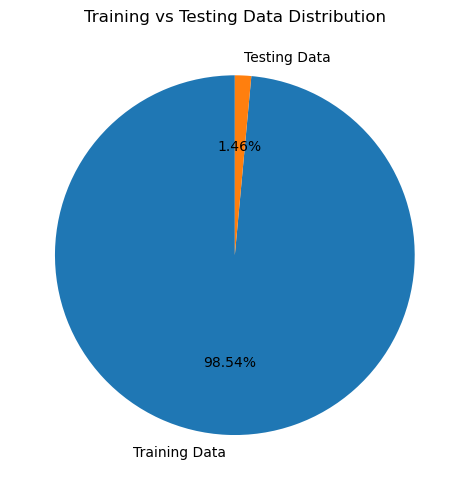

In [7]:
import matplotlib.pyplot as plt

labels = ["Training Data", "Testing Data"]
sizes = [train_percentage, test_percentage]

plt.figure(figsize=(7, 5))
plt.pie(
    sizes,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)
plt.title("Training vs Testing Data Distribution")
plt.tight_layout()
plt.show()

## Building our first Forecasting Baseline

##### NAIVE BASELINE :-If last Tuesday sold 40 units, predict 40 for this Tuesday. It needs no training, no parameters, and no math, yet it is surprisingly hard to beat on retail data with strong weekday patterns.

In [8]:
# Seasonal naive baseline: use sales from 7 days earlier
#Predict that today’s sales will equal the sales from exactly 7 days ago.
df = df.sort_values(["id", "date"]).copy()

df["naive_prediction"] = (
    df.groupby("id")["sales"].shift(7)
)

# Extract predictions for the test period
test_df = df[df["date"] >= cutoff_date].copy()

print("Test shape:", test_df.shape)
test_df[["id", "date", "sales", "naive_prediction"]].head(10)

Test shape: (28000, 27)


,id,date,sales,naive_prediction
1885000,FOODS_1_003_TX_3_validation,2016-03-28,0,0.0
1886000,FOODS_1_003_TX_3_validation,2016-03-29,0,0.0
1887000,FOODS_1_003_TX_3_validation,2016-03-30,0,1.0
1888000,FOODS_1_003_TX_3_validation,2016-03-31,0,0.0
1889000,FOODS_1_003_TX_3_validation,2016-04-01,0,0.0
1890000,FOODS_1_003_TX_3_validation,2016-04-02,0,0.0
1891000,FOODS_1_003_TX_3_validation,2016-04-03,0,2.0
1892000,FOODS_1_003_TX_3_validation,2016-04-04,0,0.0
1893000,FOODS_1_003_TX_3_validation,2016-04-05,0,0.0
1894000,FOODS_1_003_TX_3_validation,2016-04-06,0,0.0


In [9]:
print("Missing predictions:", test_df["naive_prediction"].isna().sum())
print("Actual sales total:", test_df["sales"].sum())
print("Predicted sales total:", test_df["naive_prediction"].sum())

Missing predictions: 0
Actual sales total: 33720
Predicted sales total: 33738.0


##### The difference is 33,738 − 33,720 = 18 units, which is about 0.05% of actual sales. In other words, the baseline’s overall bias is almost zero: it neither over- nor under-forecasts in total.

### Calculate WAPE 

##### WAPE means Weighted Absolute Percentage Error. Lower is better.

##### WAPE=∑|Actual−Predicted|​×100/ ∑|actual|

In [10]:
from sklearn.metrics import mean_absolute_error
import numpy as np

actual = test_df["sales"].to_numpy()
predicted = test_df["naive_prediction"].to_numpy()

wape = (
    np.abs(actual - predicted).sum()
    / np.abs(actual).sum()
) * 100

mae = mean_absolute_error(actual, predicted)

print(f"Seasonal Naive WAPE: {wape:.2f}%")
print(f"Seasonal Naive MAE:  {mae:.4f}")

Seasonal Naive WAPE: 90.96%
Seasonal Naive MAE:  1.0954


##### The sum of absolute prediction errors is 90.96% of total actual sales. This gives us a baseline to compare against our next models.

### Visualize actual vs predicted demand

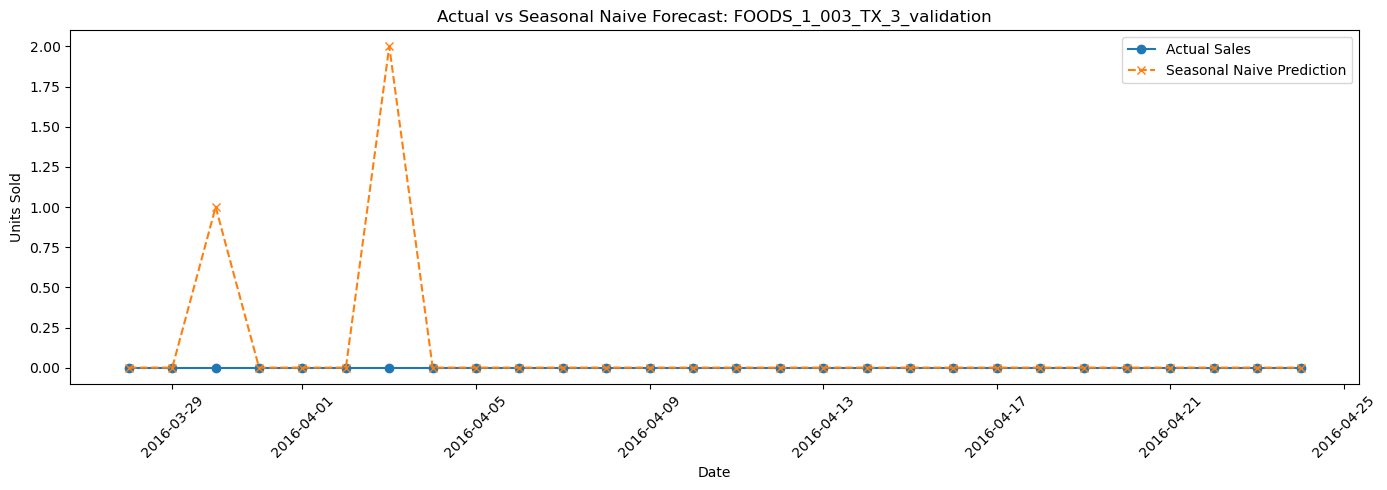

In [11]:
import matplotlib.pyplot as plt

example_id = test_df["id"].iloc[0]

plot_df = test_df[test_df["id"] == example_id].sort_values("date")

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["date"],
    plot_df["sales"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    plot_df["date"],
    plot_df["naive_prediction"],
    label="Seasonal Naive Prediction",
    linestyle="--",
    marker="x"
)

plt.title(f"Actual vs Seasonal Naive Forecast: {example_id}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Actual _vs_naive_forecast.png", dpi=300, bbox_inches="tight")
plt.show()

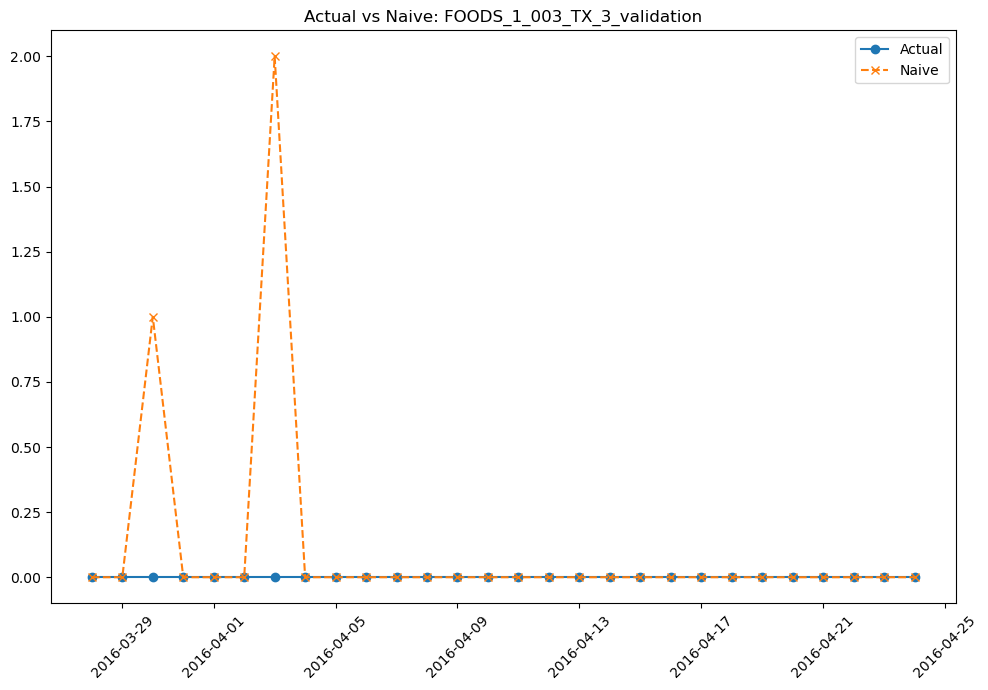

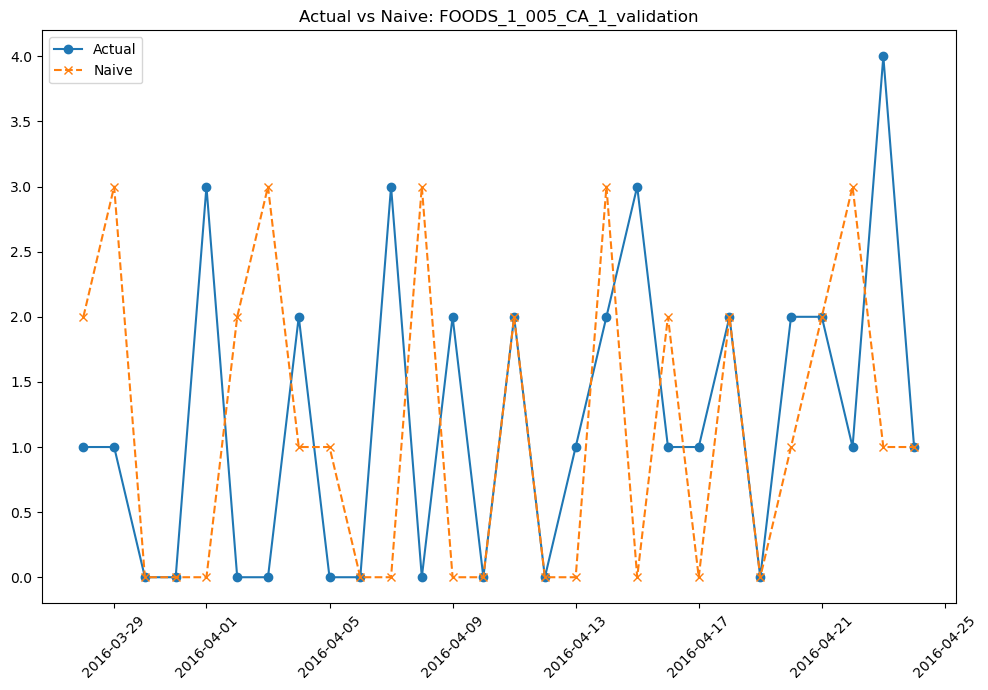

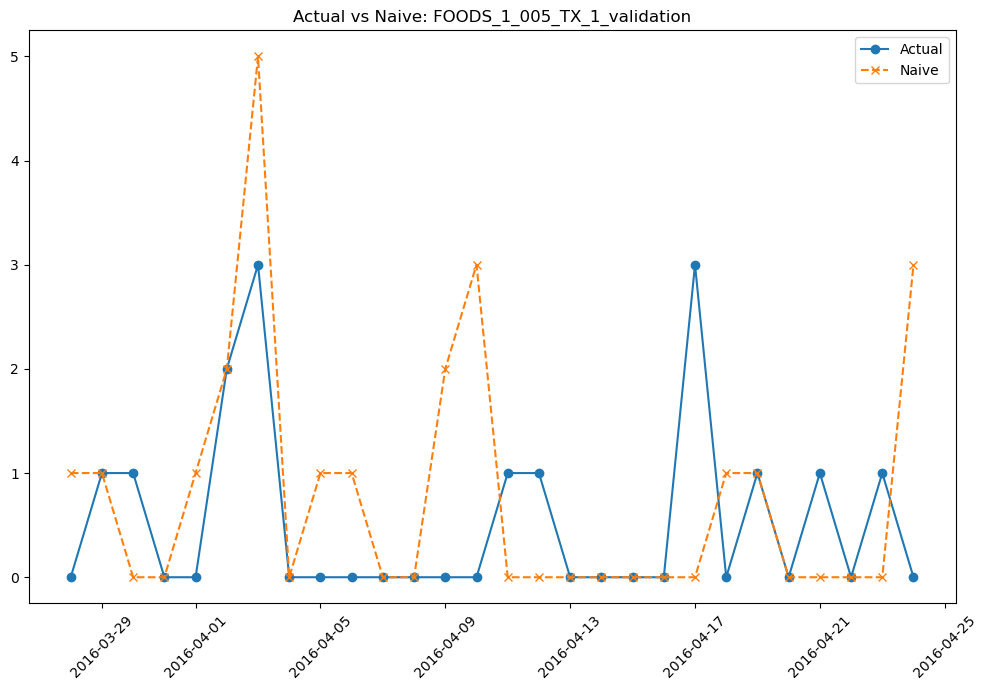

In [12]:
for pid in test_df["id"].unique()[:3]:
    p = test_df[test_df["id"] == pid].sort_values("date")
    plt.figure(figsize=(10, 7))
    plt.plot(p["date"], p["sales"], marker="o", label="Actual")
    plt.plot(p["date"], p["naive_prediction"], "--x", label="Naive")
    plt.title(f"Actual vs Naive: {pid}")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig("multiple_Actual _vs_naive_forecast.png", dpi=300, bbox_inches="tight")
    plt.show()

### Save the baseline result

In [13]:
baseline_results = pd.DataFrame({
    "Model": ["Seasonal Naive"],
    "WAPE (%)": [wape],
    "MAE": [mae]
})

baseline_results

,Model,WAPE (%),MAE
0,Seasonal Naive,90.960854,1.095429


In [14]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

baseline_results.to_csv(
    output_dir / "baseline_results.csv",
    index=False
)

print("Baseline results saved successfully.")

Baseline results saved successfully.


## LINEAR REGRESSION 

### importing lib

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

### Creating Features

In [16]:
features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

target = "sales"

### Creating modeling data(removing nan data) and verifying

In [17]:
model_df = df.dropna(subset=features + [target]).copy()

print("Original shape:", df.shape)
print("Model-ready shape:", model_df.shape)
print("Missing feature values:", model_df[features].isnull().sum().sum())

Original shape: (1913000, 27)
Model-ready shape: (1885000, 27)
Missing feature values: 0


### Spliting training testing data

##### why I used series in y :-target is a single column name (a string), so model_df[target] returns a Series (1-D), not a DataFrame

##### Because scikit-learn models expect the target y as a 1-D array of shape (n_samples,), one label per row.

In [18]:
train_model = model_df[model_df["date"] < cutoff_date].copy()
test_model = model_df[model_df["date"] >= cutoff_date].copy()

X_train = train_model[features]
y_train = train_model[target]

X_test = test_model[features]
y_test = test_model[target]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1857000, 11)
X_test: (28000, 11)
y_train: (1857000,)
y_test: (28000,)


### Applied Linear regression

In [19]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

lr_predictions = np.clip(lr_model.predict(X_test), 0, None)

lr_wape = (
    np.abs(y_test.to_numpy() - lr_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

lr_mae = mean_absolute_error(y_test, lr_predictions)

print(f"Linear Regression WAPE: {lr_wape:.2f}%")
print(f"Linear Regression MAE: {lr_mae:.4f}")

Linear Regression WAPE: 76.62%
Linear Regression MAE: 0.9227


### Applied random forest

In [20]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = np.clip(rf_model.predict(X_test), 0, None)

rf_wape = (
    np.abs(y_test.to_numpy() - rf_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

rf_mae = mean_absolute_error(y_test, rf_predictions)

print(f"Random Forest WAPE: {rf_wape:.2f}%")
print(f"Random Forest MAE: {rf_mae:.4f}")

Random Forest WAPE: 74.55%
Random Forest MAE: 0.8977


### Model Comparision 

In [21]:
model_results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "WAPE (%)": wape,
        "MAE": mae
    },
    {
        "Model": "Linear Regression",
        "WAPE (%)": lr_wape,
        "MAE": lr_mae
    },
    {
        "Model": "Random Forest",
        "WAPE (%)": rf_wape,
        "MAE": rf_mae
    }
])

model_results = model_results.sort_values("WAPE (%)")

model_results

,Model,WAPE (%),MAE
2,Random Forest,74.546188,0.897749
1,Linear Regression,76.616190,0.922678
0,Seasonal Naive,90.960854,1.095429


In [22]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully.")

Model comparison saved successfully.


# LIGHTGBM

In [23]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


### Imported libs and trained it

In [24]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error

lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgb_model.fit(X_train, y_train)

lgb_predictions = np.clip(
    lgb_model.predict(X_test),
    0,
    None
)

lgb_wape = (
    np.abs(y_test.to_numpy() - lgb_predictions).sum()
    / np.abs(y_test.to_numpy()).sum()
) * 100

lgb_mae = mean_absolute_error(y_test, lgb_predictions)

print(f"LightGBM WAPE: {lgb_wape:.2f}%")
print(f"LightGBM MAE: {lgb_mae:.4f}")

LightGBM WAPE: 74.76%
LightGBM MAE: 0.9003


### Comparing LIGHTGBM with other Baseline Models

In [25]:
model_results = pd.DataFrame([
    {"Model": "Seasonal Naive", "WAPE (%)": wape, "MAE": mae},
    {"Model": "Linear Regression", "WAPE (%)": lr_wape, "MAE": lr_mae},
    {"Model": "Random Forest", "WAPE (%)": rf_wape, "MAE": rf_mae},
    {"Model": "LightGBM", "WAPE (%)": lgb_wape, "MAE": lgb_mae}
])

model_results = model_results.sort_values("WAPE (%)").reset_index(drop=True)

model_results

,Model,WAPE (%),MAE
0,Random Forest,74.546188,0.897749
1,LightGBM,74.755753,0.900273
2,Linear Regression,76.616190,0.922678
3,Seasonal Naive,90.960854,1.095429


### Saved the report

In [26]:
model_results.to_csv(
    "../reports/model_comparison.csv",
    index=False
)

print("Updated model comparison saved!")

Updated model comparison saved!


#### Root Mean Squared Scaled Error :- It measures your model’s forecast error relative to a naive forecast . A value below 1 means your model beats the naive forecast; above 1 means it’s worse.

In [27]:
### Putting Rmsse into 

In [28]:
import numpy as np

def calculate_rmsse(train_actual, test_actual, test_predicted):
    """
    Calculate RMSSE using a one-step naive scaling denominator.
    """

    numerator = np.mean(
        (np.asarray(test_actual) - np.asarray(test_predicted)) ** 2
    )

    denominator = np.mean(
        np.diff(np.asarray(train_actual)) ** 2
    )

    if denominator == 0:
        return np.nan

    return np.sqrt(numerator / denominator)

### THis code computes the average RMSSE across all products

In [29]:
def calculate_mean_series_rmsse(train_df, test_df, prediction_column):
    train_groups = {
        product_id: group.sort_values("date")["sales"].to_numpy()
        for product_id, group in train_df.groupby("id")
    }

    scores = []

    for product_id, group in test_df.groupby("id"):
        train_sales = train_groups.get(product_id)

        if train_sales is None or len(train_sales) < 2:
            continue

        group = group.sort_values("date")
        actual = group["sales"].to_numpy()
        predicted = group[prediction_column].to_numpy()

        denominator = np.mean(np.diff(train_sales) ** 2)

        if denominator == 0:
            continue

        score = np.sqrt(np.mean((actual - predicted) ** 2) / denominator)
        scores.append(score)

    return np.mean(scores) if scores else np.nan

#### score is the mean RMSSE across all valid products.

In [30]:
score = calculate_mean_series_rmsse(
    train_df,
    test_df,
    "naive_prediction"
)

print(f"Seasonal Naive RMSSE: {score:.4f}")

Seasonal Naive RMSSE: 1.1786


### Compare Model performance

In [31]:
# Check which prediction variables exist in memory

prediction_variables = [
    "lr_predictions",
    "lr_price_predictions",
    "rf_predictions",
    "rf_price_predictions",
    "lgb_predictions",
    "lgb_price_predictions"
]

for name in prediction_variables:
    if name in globals():
        value = globals()[name]
        print(f"{name}: EXISTS | Length: {len(value)}")
    else:
        print(f"{name}: NOT FOUND")

lr_predictions: EXISTS | Length: 28000
lr_price_predictions: NOT FOUND
rf_predictions: EXISTS | Length: 28000
rf_price_predictions: NOT FOUND
lgb_predictions: EXISTS | Length: 28000
lgb_price_predictions: NOT FOUND


In [32]:
print("test_df shape:", test_df.shape)
print("test_model shape:", test_model.shape)

print("\nBaseline prediction lengths:")
print("Linear Regression:", len(lr_predictions))
print("Random Forest:", len(rf_predictions))
print("LightGBM:", len(lgb_predictions))

print("\nAvailable prediction columns in test_df:")
print([
    col for col in test_df.columns
    if "prediction" in col.lower()
])

test_df shape: (28000, 27)
test_model shape: (28000, 27)

Baseline prediction lengths:
Linear Regression: 28000
Random Forest: 28000
LightGBM: 28000

Available prediction columns in test_df:
['naive_prediction']


### added each model’s predictions as new columns in the test DataFrame

In [33]:
# Attach existing baseline predictions to their matching test rows

test_model = test_model.copy()

test_model["lr_prediction"] = lr_predictions
test_model["rf_prediction"] = rf_predictions
test_model["lgb_prediction"] = lgb_predictions

print("Prediction columns added successfully.")
print(
    test_model[
        ["sales", "lr_prediction", "rf_prediction", "lgb_prediction"]
    ].head()
)

print("\nShape:", test_model.shape)

Prediction columns added successfully.
         sales  lr_prediction  rf_prediction  lgb_prediction
1885000      0       0.494534       0.643631        0.354815
1886000      0       0.130311       0.235335        0.223641
1887000      0       0.195017       0.226934        0.209817
1888000      0       0.164957       0.180341        0.206471
1889000      0       0.268651       0.182745        0.262942

Shape: (28000, 30)


### Compared Rmsse of all models 

In [34]:
rmsse_results = {
    "Seasonal Naive": calculate_mean_series_rmsse(
        train_df, test_df, "naive_prediction"
    ),
    "Linear Regression": calculate_mean_series_rmsse(
        train_df, test_model, "lr_prediction"
    ),
    "Random Forest": calculate_mean_series_rmsse(
        train_df, test_model, "rf_prediction"
    ),
    "LightGBM": calculate_mean_series_rmsse(
        train_df, test_model, "lgb_prediction"
    )
}

print("Baseline RMSSE Results:")
for model, score in rmsse_results.items():
    print(f"{model}: {score:.4f}")

Baseline RMSSE Results:
Seasonal Naive: 1.1786
Linear Regression: 0.9048
Random Forest: 0.8688
LightGBM: 0.8727


### Created a comparison report 

In [35]:
model_results = pd.DataFrame([
    {
        "Model": "Seasonal Naive",
        "WAPE (%)": wape,
        "MAE": mae,
        "RMSSE": rmsse_results.get("Seasonal Naive", np.nan)
    },
    {
        "Model": "Linear Regression",
        "WAPE (%)": lr_wape,
        "MAE": lr_mae,
        "RMSSE": rmsse_results.get("Linear Regression", np.nan)
    },
    {
        "Model": "Random Forest",
        "WAPE (%)": rf_wape,
        "MAE": rf_mae,
        "RMSSE": rmsse_results.get("Random Forest", np.nan)
    },
    {
        "Model": "LightGBM",
        "WAPE (%)": lgb_wape,
        "MAE": lgb_mae,
        "RMSSE": rmsse_results.get("LightGBM", np.nan)
    }
])

model_results = model_results.sort_values("WAPE (%)").reset_index(drop=True)

display(model_results)

,Model,WAPE (%),MAE,RMSSE
0,Random Forest,74.546188,0.897749,0.868765
1,LightGBM,74.755753,0.900273,0.872687
2,Linear Regression,76.616190,0.922678,0.904799
3,Seasonal Naive,90.960854,1.095429,1.178628


### Visualized our comparison report of WAPE 

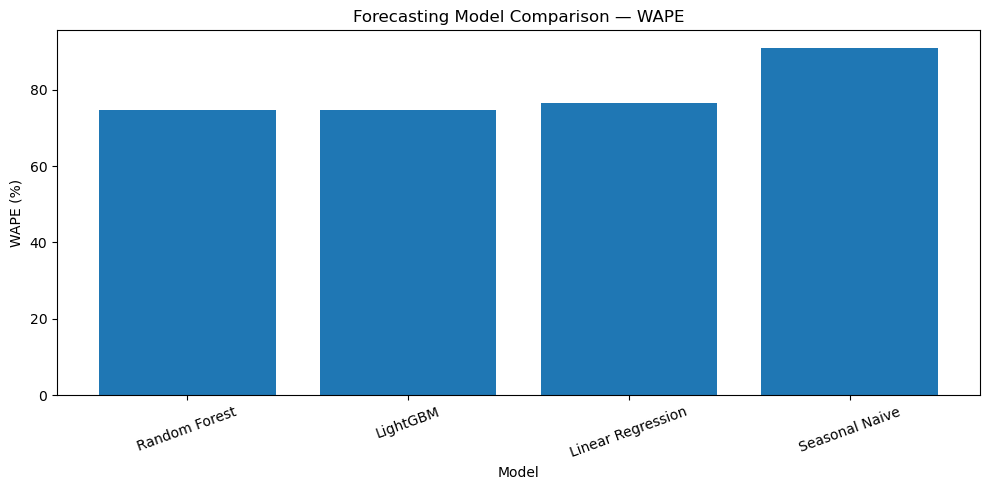

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(model_results["Model"], model_results["WAPE (%)"])

plt.title("Forecasting Model Comparison — WAPE")
plt.xlabel("Model")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Visualized our comparison report of MAE

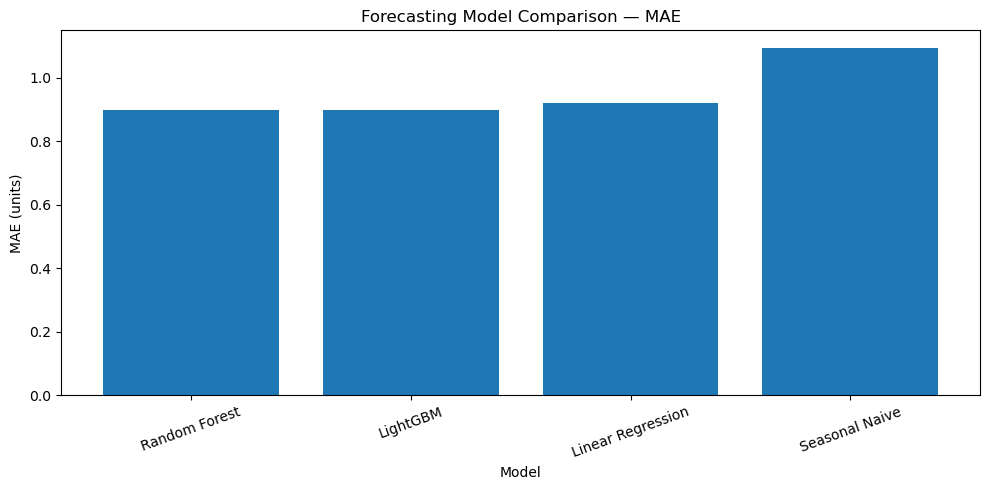

In [37]:
plt.figure(figsize=(10, 5))

plt.bar(model_results["Model"], model_results["MAE"])

plt.title("Forecasting Model Comparison — MAE")
plt.xlabel("Model")
plt.ylabel("MAE (units)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

### Saved it 

In [38]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

model_results.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [39]:
model_results.sort_values("WAPE (%)")

,Model,WAPE (%),MAE,RMSSE
0,Random Forest,74.546188,0.897749,0.868765
1,LightGBM,74.755753,0.900273,0.872687
2,Linear Regression,76.616190,0.922678,0.904799
3,Seasonal Naive,90.960854,1.095429,1.178628


# Add selling-price feautures

### Loaded Price and calendar data 

##### here wm_yr_wk is Walmart year-week ID :- the first 3 digits are a year code (111 ≈ 2011) and the last 2 are the week number (01) for 11101.

In [40]:
from pathlib import Path
import pandas as pd

# Load price and calendar data
prices = pd.read_csv("../data/raw/m5-forecasting-accuracy/sell_prices.csv")
calendar = pd.read_csv("../data/raw/m5-forecasting-accuracy/calendar.csv")

print("Prices shape:", prices.shape)
print("Calendar shape:", calendar.shape)

print("\nPrice columns:")
print(prices.columns.tolist())

print("\nCalendar columns:")
print(calendar[["d", "date", "wm_yr_wk"]].head())

Prices shape: (6841121, 4)
Calendar shape: (1969, 14)

Price columns:
['store_id', 'item_id', 'wm_yr_wk', 'sell_price']

Calendar columns:
     d        date  wm_yr_wk
0  d_1  2011-01-29     11101
1  d_2  2011-01-30     11101
2  d_3  2011-01-31     11101
3  d_4  2011-02-01     11101
4  d_5  2011-02-02     11101


### selected needed col, Merged price and calendar 

In [41]:
# Keep only the columns needed for the merge
price_data = prices[
    ["store_id", "item_id", "wm_yr_wk", "sell_price"]
].copy()

calendar_data = calendar[["d", "wm_yr_wk"]].copy()

# Add week information to daily sales
sales_with_calendar = df.merge(
    calendar_data,
    left_on="d",
    right_on="d",
    how="left",
    validate="many_to_one"
)

# Merge selling prices
sales_with_prices = sales_with_calendar.merge(
    price_data,
    on=["store_id", "item_id", "wm_yr_wk"],
    how="left",
    validate="many_to_one"
)

print("Original rows:", len(df))
print("Rows after merging:", len(sales_with_prices))
print("Missing selling prices:", sales_with_prices["sell_price"].isna().sum())

sales_with_prices.head()

Original rows: 1913000
Rows after merging: 1913000
Missing selling prices: 420812


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,day_number,lag_1,...,event_type_2,snap_CA,snap_TX,snap_WI,day_of_week,month,is_event,naive_prediction,wm_yr_wk,sell_price
0,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_1,1,1,NaN,...,None,0,0,0,5,1,0,NaN,11101,2.88
1,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_2,0,2,1.0,...,None,0,0,0,6,1,0,NaN,11101,2.88
2,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_3,0,3,0.0,...,None,0,0,0,0,1,0,NaN,11101,2.88
3,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_4,2,4,0.0,...,None,1,1,0,1,2,0,NaN,11101,2.88
4,FOODS_1_003_TX_3_validation,FOODS_1_003,FOODS_1,FOODS,TX_3,TX,d_5,0,5,2.0,...,None,1,0,1,2,2,0,NaN,11101,2.88


### Created Price change features, it affects sales

In [42]:
# Sort each product-store series chronologically
sales_with_prices = sales_with_prices.sort_values(
    ["id", "date"]
).copy()

# Previous week's selling price
sales_with_prices["previous_price"] = (
    sales_with_prices.groupby("id")["sell_price"].shift(7)
)

# Percentage change relative to previous week's price
sales_with_prices["price_change_pct"] = (
    (
        sales_with_prices["sell_price"]
        - sales_with_prices["previous_price"]
    )
    / sales_with_prices["previous_price"].replace(0, np.nan)
) * 100

# Price change indicator
sales_with_prices["price_changed"] = (
    sales_with_prices["sell_price"]
    != sales_with_prices["previous_price"]
).astype("int8")

print("Dataset shape:", sales_with_prices.shape)

print("\nMissing current prices:",
      sales_with_prices["sell_price"].isna().sum())

print("\nPrice-change summary:")
print(sales_with_prices["price_change_pct"].describe().round(2))

print("\nPrice-change examples:")
print(
    sales_with_prices[
        ["id", "date", "sell_price", "previous_price",
         "price_change_pct", "price_changed"]
    ].head(10)
)

Dataset shape: (1913000, 32)

Missing current prices: 420812

Price-change summary:
count    1485188.00
mean           0.07
std            6.83
min          -95.97
25%            0.00
50%            0.00
75%            0.00
max         2380.00
Name: price_change_pct, dtype: float64

Price-change examples:
                            id       date  sell_price  previous_price  \
0  FOODS_1_003_TX_3_validation 2011-01-29        2.88             NaN   
1  FOODS_1_003_TX_3_validation 2011-01-30        2.88             NaN   
2  FOODS_1_003_TX_3_validation 2011-01-31        2.88             NaN   
3  FOODS_1_003_TX_3_validation 2011-02-01        2.88             NaN   
4  FOODS_1_003_TX_3_validation 2011-02-02        2.88             NaN   
5  FOODS_1_003_TX_3_validation 2011-02-03        2.88             NaN   
6  FOODS_1_003_TX_3_validation 2011-02-04        2.88             NaN   
7  FOODS_1_003_TX_3_validation 2011-02-05        2.88            2.88   
8  FOODS_1_003_TX_3_validation 2011-

### Fixed Nan issue

##### it makes price_changed equal 1 only when there’s a real price change.

In [43]:
sales_with_prices["price_changed"] = (
    sales_with_prices["sell_price"]
    .ne(sales_with_prices["previous_price"])
    & sales_with_prices["previous_price"].notna()
    & sales_with_prices["sell_price"].notna()
).astype("int8")

print(sales_with_prices["price_changed"].value_counts())

price_changed
0    1896355
1      16645
Name: count, dtype: int64


### Created report for price , price changed and price change percent 

In [44]:
price_columns = [
    "sell_price",
    "previous_price",
    "price_change_pct",
    "price_changed"
]

print("Missing values:")
print(sales_with_prices[price_columns].isnull().sum())

print("\nPrice change indicator:")
print(sales_with_prices["price_changed"].value_counts())

print("\nPrice change percentage summary:")
print(sales_with_prices["price_change_pct"].describe())

Missing values:
sell_price          420812
previous_price      427812
price_change_pct    427812
price_changed            0
dtype: int64

Price change indicator:
price_changed
0    1896355
1      16645
Name: count, dtype: int64

Price change percentage summary:
count    1.485188e+06
mean     6.881190e-02
std      6.826779e+00
min     -9.596774e+01
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      2.380000e+03
Name: price_change_pct, dtype: float64


### investigates where the missing sell_price values are

In [45]:
print("Missing current prices by category:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna()
    ].groupby("cat_id").size()
)

print("\nMissing current prices by state:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna()
    ].groupby("state_id").size()
)

print("\nExamples of missing prices:")
print(
    sales_with_prices.loc[
        sales_with_prices["sell_price"].isna(),
        ["id", "item_id", "store_id", "state_id", "d", "wm_yr_wk"]
    ].head(10)
)

Missing current prices by category:
cat_id
FOODS        196763
HOBBIES       87451
HOUSEHOLD    136598
dtype: int64

Missing current prices by state:
state_id
CA    178787
TX    120001
WI    122024
dtype: int64

Examples of missing prices:
                               id      item_id store_id state_id     d  \
7652  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_1   
7653  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_2   
7654  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_3   
7655  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_4   
7656  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_5   
7657  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_6   
7658  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_7   
7659  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_8   
7660  FOODS_1_008_CA_2_validation  FOODS_1_008     CA_2       CA   d_9   
7661  FOODS_1_008_CA

#### a quick health check before training. They show the shape, how many NaNs each price feature has, and all available columns so you can pick your final features.

In [46]:
model_df = sales_with_prices.copy()

price_features = [
    "sell_price",
    "price_change_pct",
    "price_changed"
]

print("Dataset shape:", model_df.shape)

print("\nPrice feature missing values:")
print(model_df[price_features].isnull().sum())

print("\nAvailable columns:")
print(model_df.columns.tolist())

Dataset shape: (1913000, 32)

Price feature missing values:
sell_price          420812
price_change_pct    427812
price_changed            0
dtype: int64

Available columns:
['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd', 'sales', 'day_number', 'lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'date', 'weekday', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI', 'day_of_week', 'month', 'is_event', 'naive_prediction', 'wm_yr_wk', 'sell_price', 'previous_price', 'price_change_pct', 'price_changed']


### report of  missing price summary 

In [47]:
# Check whether missing prices are concentrated in specific categories
missing_price_summary = (
    model_df.assign(
        price_missing=model_df["sell_price"].isna()
    )
    .groupby("cat_id")
    .agg(
        total_rows=("sell_price", "size"),
        missing_prices=("price_missing", "sum")
    )
)

missing_price_summary["missing_percentage"] = (
    missing_price_summary["missing_prices"]
    / missing_price_summary["total_rows"]
    * 100
)

print(missing_price_summary)

           total_rows  missing_prices  missing_percentage
cat_id                                                   
FOODS          906762          196763           21.699520
HOBBIES        384513           87451           22.743314
HOUSEHOLD      621725          136598           21.970807


In [48]:
missing_by_week = (
    model_df[model_df["sell_price"].isna()]
    .groupby("wm_yr_wk")
    .size()
    .sort_values(ascending=False)
)

print("Weeks with the most missing prices:")
print(missing_by_week.head(10))

print("\nTotal unique weeks:", model_df["wm_yr_wk"].nunique())

print("\nMissing prices by state:")
print(
    model_df[model_df["sell_price"].isna()]
    .groupby("state_id")
    .size()
)

Weeks with the most missing prices:
wm_yr_wk
11101    4550
11102    4326
11103    4200
11104    4095
11105    4004
11106    3941
11107    3871
11108    3850
11109    3794
11110    3745
dtype: int64

Total unique weeks: 274

Missing prices by state:
state_id
CA    178787
TX    120001
WI    122024
dtype: int64


 ### The item-store pair exists in prices:- this means the item hadn’t launched(sold) yet

In [49]:
# Check whether missing-price rows have a matching item-store pair
price_pairs = prices[["store_id", "item_id"]].drop_duplicates()

price_check = model_df.loc[
    model_df["sell_price"].isna(),
    ["store_id", "item_id", "wm_yr_wk"]
].merge(
    price_pairs.assign(pair_exists=True),
    on=["store_id", "item_id"],
    how="left"
)

print("Missing-price rows:", len(price_check))

print("\nItem-store pairs that exist in the price dataset:")
print(price_check["pair_exists"].eq(True).sum())

print("\nItem-store pairs absent from the price dataset:")
print(price_check["pair_exists"].isna().sum())

Missing-price rows: 420812

Item-store pairs that exist in the price dataset:
420812

Item-store pairs absent from the price dataset:
0


### A Real example for inspection 

In [50]:
# Select one item-store pair with a missing price
missing_example = model_df.loc[
    model_df["sell_price"].isna(),
    ["item_id", "store_id", "wm_yr_wk"]
].iloc[0]

item = missing_example["item_id"]
store = missing_example["store_id"]
week = missing_example["wm_yr_wk"]

print("Item:", item)
print("Store:", store)
print("Week with missing price:", week)

print("\nAvailable prices for this item-store pair:")
print(
    prices.loc[
        (prices["item_id"] == item)
        & (prices["store_id"] == store)
    ].sort_values("wm_yr_wk").head(15)
)

Item: FOODS_1_008
Store: CA_2
Week with missing price: 11101

Available prices for this item-store pair:
        store_id      item_id  wm_yr_wk  sell_price
1066742     CA_2  FOODS_1_008     11201        3.28
1066743     CA_2  FOODS_1_008     11202        3.28
1066744     CA_2  FOODS_1_008     11203        3.28
1066745     CA_2  FOODS_1_008     11204        3.28
1066746     CA_2  FOODS_1_008     11205        3.28
1066747     CA_2  FOODS_1_008     11206        3.28
1066748     CA_2  FOODS_1_008     11207        3.28
1066749     CA_2  FOODS_1_008     11208        3.28
1066750     CA_2  FOODS_1_008     11209        3.28
1066751     CA_2  FOODS_1_008     11210        3.28
1066752     CA_2  FOODS_1_008     11211        3.28
1066753     CA_2  FOODS_1_008     11212        3.28
1066754     CA_2  FOODS_1_008     11213        3.28
1066755     CA_2  FOODS_1_008     11214        3.28
1066756     CA_2  FOODS_1_008     11215        3.28


### Inspected the date range where the item actually had a price in that store.

In [51]:
item_prices = prices[
    (prices["item_id"] == item)
    & (prices["store_id"] == store)
].sort_values("wm_yr_wk")

print("First available price week:", item_prices["wm_yr_wk"].min())
print("Last available price week:", item_prices["wm_yr_wk"].max())

print("\nPrice history:")
print(item_prices[["wm_yr_wk", "sell_price"]].head(5))

print("\nNumber of weeks with recorded prices:", len(item_prices))

First available price week: 11201
Last available price week: 11621

Price history:
         wm_yr_wk  sell_price
1066742     11201        3.28
1066743     11202        3.28
1066744     11203        3.28
1066745     11204        3.28
1066746     11205        3.28

Number of weeks with recorded prices: 230


###### if week is below 11201, the NaN is just a pre-launch row, not bad data. Those rows should have sales = 0, so you can safely drop them (or leave them as NaN for LightGBM). Don’t fill them with 0.

### Price coverage :- the percentage of rows that have a sell_price

In [52]:
price_coverage = (
    sales_with_prices
    .groupby("state_id")
    .agg(
        total_rows=("sales", "size"),
        available_prices=("sell_price", "count")
    )
)

price_coverage["price_coverage_pct"] = (
    price_coverage["available_prices"]
    / price_coverage["total_rows"]
    * 100
).round(2)

print(price_coverage)

print(
    "\nOverall price coverage:",
    round(sales_with_prices["sell_price"].notna().mean() * 100, 2),
    "%"
)

          total_rows  available_prices  price_coverage_pct
state_id                                                  
CA            778591            599804               77.04
TX            583465            463464               79.43
WI            550944            428920               77.85

Overall price coverage: 78.0 %


## Time Based Train- Test Split 

In [53]:
model_df = sales_with_prices.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(model_df["date"].unique())

split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = model_df[model_df["date"] < split_date].copy()
test_df = model_df[model_df["date"] >= split_date].copy()

print("Split date:", split_date)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nTraining date range:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nTesting date range:")
print(test_df["date"].min(), "to", test_df["date"].max())

Split date: 2015-04-08 00:00:00
Training rows: 1530000
Testing rows: 383000

Training date range:
2011-01-29 00:00:00 to 2015-04-07 00:00:00

Testing date range:
2015-04-08 00:00:00 to 2016-04-24 00:00:00


### Inspected Dataset with price feauture and found 420812 missing values

In [54]:
# Create a separate copy for the price-feature experiment
price_model_df = sales_with_prices.copy()

# Add an indicator for missing prices
price_model_df["price_missing"] = (
    price_model_df["sell_price"].isna()
).astype("int8")

# Check the new features
print("Dataset shape:", price_model_df.shape)

print("\nMissing-price indicator:")
print(price_model_df["price_missing"].value_counts())

print("\nPrice feature summary:")
print(
    price_model_df[
        ["sell_price", "price_change_pct", "price_changed", "price_missing"]
    ].describe()
)

Dataset shape: (1913000, 33)

Missing-price indicator:
price_missing
0    1492188
1     420812
Name: count, dtype: int64

Price feature summary:
         sell_price  price_change_pct  price_changed  price_missing
count  1.492188e+06      1.485188e+06   1.913000e+06   1.913000e+06
mean   4.443153e+00      6.881190e-02   8.700993e-03   2.199749e-01
std    3.616720e+00      6.826779e+00   9.287244e-02   4.142295e-01
min    5.000000e-02     -9.596774e+01   0.000000e+00   0.000000e+00
25%    2.120000e+00      0.000000e+00   0.000000e+00   0.000000e+00
50%    3.370000e+00      0.000000e+00   0.000000e+00   0.000000e+00
75%    5.860000e+00      0.000000e+00   0.000000e+00   0.000000e+00
max    3.098000e+01      2.380000e+03   1.000000e+00   1.000000e+00


### Filled Missing Value with median prices in Our chronological Split 

In [55]:
# Create chronological training and testing sets
price_model_df = price_model_df.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(price_model_df["date"].unique())
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = price_model_df[
    price_model_df["date"] < split_date
].copy()

test_df = price_model_df[
    price_model_df["date"] >= split_date
].copy()

# Calculate fallback median using training data only
global_price_median = train_df["sell_price"].median()

# Calculate each item's median using training data only
item_store_medians = train_df.groupby("id")["sell_price"].median()

# Fill missing prices using training-derived medians
for dataset in [train_df, test_df]:
    dataset["sell_price_imputed"] = (
        dataset["sell_price"]
        .fillna(dataset["id"].map(item_store_medians))
        .fillna(global_price_median)
    )

print("Split date:", split_date)
print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))

print("\nRemaining missing prices:")
print("Train:", train_df["sell_price_imputed"].isna().sum())
print("Test:", test_df["sell_price_imputed"].isna().sum())

print("\nTraining median price:", global_price_median)

Split date: 2015-04-08 00:00:00
Training rows: 1530000
Testing rows: 383000

Remaining missing prices:
Train: 0
Test: 0

Training median price: 3.34


### finds the most extreme price jumps in your data, so we can check whether they’re real or errors before training

In [56]:
# Inspect the largest absolute price changes
extreme_price_changes = (
    price_model_df.loc[
        price_model_df["price_change_pct"].notna(),
        [
            "id",
            "date",
            "sell_price",
            "previous_price",
            "price_change_pct"
        ]
    ]
    .assign(
        absolute_change=lambda x: x["price_change_pct"].abs()
    )
    .sort_values("absolute_change", ascending=False)
)

print(extreme_price_changes.head(15).to_string(index=False))

                             id       date  sell_price  previous_price  price_change_pct  absolute_change
    FOODS_3_425_TX_3_validation 2013-06-21        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-17        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-19        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-15        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-16        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-20        2.48            0.10       2380.000000      2380.000000
    FOODS_3_425_TX_3_validation 2013-06-18        2.48            0.10       2380.000000      2380.000000
    FOODS_2_231_TX_3_validation 2014-08-27        2.75            0.20       1275.000000      1275.000000
    FOODS_2_231_TX_3_validation 2014-08-25    

### created a log price change feature

##### What it computes

##### log_price_change = ln(sell_price / previous_price)

##### No change → ln(1) = 0
##### Price doubles → about +0.69
##### Price halves → about -0.69

In [57]:
import numpy as np

# Calculate log price change only when both prices are positive
valid_prices = (
    sales_with_prices["sell_price"].gt(0)
    & sales_with_prices["previous_price"].gt(0)
)

sales_with_prices["log_price_change"] = np.nan

sales_with_prices.loc[valid_prices, "log_price_change"] = np.log(
    sales_with_prices.loc[valid_prices, "sell_price"]
    / sales_with_prices.loc[valid_prices, "previous_price"]
)

print("Log price change summary:")
print(sales_with_prices["log_price_change"].describe())

print("\nLargest absolute log price changes:")
print(
    sales_with_prices.loc[
        sales_with_prices["log_price_change"].notna(),
        ["id", "date", "sell_price", "previous_price", "log_price_change"]
    ]
    .assign(
        abs_log_change=lambda x: x["log_price_change"].abs()
    )
    .sort_values("abs_log_change", ascending=False)
    .head(10)
    .to_string(index=False)
)

Log price change summary:
count    1.485188e+06
mean     9.053984e-05
std      3.135512e-02
min     -3.210844e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      3.210844e+00
Name: log_price_change, dtype: float64

Largest absolute log price changes:
                         id       date  sell_price  previous_price  log_price_change  abs_log_change
FOODS_3_425_TX_3_validation 2013-06-10        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-09        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-13        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-14        0.10            2.48         -3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-15        2.48            0.10          3.210844        3.210844
FOODS_3_425_TX_3_validation 2013-06-16        2.48            0.10          3.210844        3.210844
FOODS_3_425_TX_

### finalizes the price features for modeling, and adds the missing-price flag

In [58]:
price_model_df = sales_with_prices.copy()

price_model_df["price_missing"] = (
    price_model_df["sell_price"].isna()
).astype("int8")

price_features = [
    "sell_price",
    "log_price_change",
    "price_changed",
    "price_missing"
]

print("Price features:", price_features)

print("\nMissing values:")
print(price_model_df[price_features].isna().sum())

print("\nDataset shape:", price_model_df.shape)

Price features: ['sell_price', 'log_price_change', 'price_changed', 'price_missing']

Missing values:
sell_price          420812
log_price_change    427812
price_changed            0
price_missing            0
dtype: int64

Dataset shape: (1913000, 34)


### Impute Price Features Without Leakage

### final prep step: 
#### the chronological split, 
#### plus filling the NaNs in the two price columns so every model can use them.
#### and it fixes the leakage-safe way.

In [59]:
# Create the chronological split
price_model_df = price_model_df.sort_values(
    ["date", "id"]
).copy()

unique_dates = sorted(price_model_df["date"].unique())
split_index = int(len(unique_dates) * 0.8)
split_date = unique_dates[split_index]

train_df = price_model_df[
    price_model_df["date"] < split_date
].copy()

test_df = price_model_df[
    price_model_df["date"] >= split_date
].copy()

# Calculate imputation values using training data only
global_price_median = train_df["sell_price"].median()
global_log_change_median = train_df["log_price_change"].median()

item_price_medians = train_df.groupby("id")["sell_price"].median()

# Impute prices using each series' training median, then global fallback
for dataset in [train_df, test_df]:
    dataset["sell_price_imputed"] = (
        dataset["sell_price"]
        .fillna(dataset["id"].map(item_price_medians))
        .fillna(global_price_median)
    )

    dataset["log_price_change_imputed"] = (
        dataset["log_price_change"]
        .fillna(global_log_change_median)
    )

print("Split date:", split_date)

print("\nRemaining missing values:")
print(
    train_df[
        ["sell_price_imputed", "log_price_change_imputed"]
    ].isna().sum()
)

print(
    test_df[
        ["sell_price_imputed", "log_price_change_imputed"]
    ].isna().sum()
)

Split date: 2015-04-08 00:00:00

Remaining missing values:
sell_price_imputed          0
log_price_change_imputed    0
dtype: int64
sell_price_imputed          0
log_price_change_imputed    0
dtype: int64


### Prepare the Model Features

In [60]:
base_features = [
    "lag_1",
    "lag_7",
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "day_of_week",
    "month",
    "is_event",
    "snap_CA",
    "snap_TX",
    "snap_WI"
]

price_features = [
    "sell_price_imputed",
    "log_price_change_imputed",
    "price_changed",
    "price_missing"
]

target = "sales"

# Keep rows with complete baseline features and valid targets
train_model = train_df.dropna(
    subset=base_features + [target]
).copy()

test_model = test_df.dropna(
    subset=base_features + [target]
).copy()

print("Training rows:", len(train_model))
print("Testing rows:", len(test_model))

print("\nBaseline feature count:", len(base_features))
print("Price feature count:", len(price_features))

print("\nMissing baseline features in training:")
print(train_model[base_features].isna().sum().sum())

print("\nMissing baseline features in testing:")
print(test_model[base_features].isna().sum().sum())

Training rows: 1502000
Testing rows: 383000

Baseline feature count: 11
Price feature count: 4

Missing baseline features in training:
0

Missing baseline features in testing:
0


## Training Random forest with price features

In [61]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np

# Features
X_train_price = train_model[base_features + price_features]
y_train = train_model[target]

X_test_price = test_model[base_features + price_features]
y_test = test_model[target]

# Train Random Forest
rf_price = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

print("Training Random Forest with price features...")

rf_price.fit(X_train_price, y_train)

print("Training completed!")

# Predictions
rf_price_predictions = np.maximum(
    rf_price.predict(X_test_price), 0
)

# Metrics
rf_price_mae = mean_absolute_error(
    y_test, rf_price_predictions
)

rf_price_wape = (
    np.abs(y_test - rf_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nRandom Forest with Price Features")
print("MAE:", round(rf_price_mae, 4))
print("WAPE:", round(rf_price_wape, 2), "%")

Training Random Forest with price features...
Training completed!

Random Forest with Price Features
MAE: 0.8845
WAPE: 76.19 %


### TRAINING LIGHTGBM 

In [62]:
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error

lgb_price = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

print("Training LightGBM with price features...")

lgb_price.fit(X_train_price, y_train)

print("Training completed!")

lgb_price_predictions = np.maximum(
    lgb_price.predict(X_test_price), 0
)

lgb_price_mae = mean_absolute_error(
    y_test, lgb_price_predictions
)

lgb_price_wape = (
    np.abs(y_test - lgb_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nLightGBM with Price Features")
print("MAE:", round(lgb_price_mae, 4))
print("WAPE:", round(lgb_price_wape, 2), "%")

Training LightGBM with price features...
Training completed!

LightGBM with Price Features
MAE: 0.8851
WAPE: 76.25 %


### TRAINING WITH LINEAR REGRESSION 

In [63]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import numpy as np

lr_price = LinearRegression()

print("Training Linear Regression with price features...")

lr_price.fit(X_train_price, y_train)

print("Training completed!")

lr_price_predictions = np.maximum(
    lr_price.predict(X_test_price), 0
)

lr_price_mae = mean_absolute_error(
    y_test, lr_price_predictions
)

lr_price_wape = (
    np.abs(y_test - lr_price_predictions).sum()
    / np.abs(y_test).sum()
) * 100

print("\nLinear Regression with Price Features")
print("MAE:", round(lr_price_mae, 4))
print("WAPE:", round(lr_price_wape, 2), "%")

Training Linear Regression with price features...
Training completed!

Linear Regression with Price Features
MAE: 0.9078
WAPE: 78.19 %


## Analyze Prize Impact 

### analyze price changes and sales

In [64]:
# Analyze sales when prices change vs. when they remain stable

price_impact = (
    sales_with_prices
    .groupby("price_changed")
    .agg(
        total_days=("sales", "count"),
        average_sales=("sales", "mean"),
        median_sales=("sales", "median"),
        total_sales=("sales", "sum")
    )
    .reset_index()
)

price_impact["price_status"] = price_impact["price_changed"].map({
    0: "No price change / insufficient price history",
    1: "Price changed"
})

price_impact

,price_changed,total_days,average_sales,median_sales,total_sales,price_status
0,0,1896355,0.986853,0.0,1871424,No price change / insufficient price history
1,1,16645,1.636407,0.0,27238,Price changed


In [65]:
for status, group in sales_with_prices.groupby("price_changed"):
    label = "Price changed" if status == 1 else "No detected price change"

    print(f"\n{label}")
    print(f"Number of rows: {len(group):,}")
    print(f"Average sales: {group['sales'].mean():.4f}")
    print(f"Median sales: {group['sales'].median():.4f}")
    print(f"Total sales: {group['sales'].sum():,.0f}")


No detected price change
Number of rows: 1,896,355
Average sales: 0.9869
Median sales: 0.0000
Total sales: 1,871,424

Price changed
Number of rows: 16,645
Average sales: 1.6364
Median sales: 0.0000
Total sales: 27,238


In [66]:
# Calculate the change in sales for each item-store series
sales_with_prices = sales_with_prices.sort_values(
    ["id", "date"]
).copy()

sales_with_prices["previous_sales"] = (
    sales_with_prices.groupby("id")["sales"].shift(1)
)

# Keep only rows with a detected price change and valid previous sales
price_change_analysis = sales_with_prices[
    (sales_with_prices["price_changed"] == 1)
    & (sales_with_prices["previous_sales"].notna())
].copy()

price_change_analysis["sales_change"] = (
    price_change_analysis["sales"]
    - price_change_analysis["previous_sales"]
)

price_change_analysis["sales_direction"] = np.select(
    [
        price_change_analysis["sales_change"] > 0,
        price_change_analysis["sales_change"] < 0
    ],
    [
        "Sales increased",
        "Sales decreased"
    ],
    default="Sales unchanged"
)

print("Sales direction on detected price-change days:")
display(
    price_change_analysis["sales_direction"]
    .value_counts()
    .rename_axis("sales_direction")
    .reset_index(name="observations")
)

Sales direction on detected price-change days:


,sales_direction,observations
0,Sales unchanged,7955
1,Sales increased,4826
2,Sales decreased,3864


In [67]:
category_price_analysis = (
    price_change_analysis
    .groupby("cat_id")
    .agg(
        price_change_days=("sales", "size"),
        average_sales=("sales", "mean"),
        average_previous_sales=("previous_sales", "mean"),
        average_sales_change=("sales_change", "mean")
    )
    .reset_index()
)

display(category_price_analysis.round(4))

,cat_id,price_change_days,average_sales,average_previous_sales,average_sales_change
0,FOODS,10932,1.9705,1.7003,0.2701
1,HOBBIES,2484,1.1981,1.0491,0.1490
2,HOUSEHOLD,3229,0.8427,0.7070,0.1356


### VISUALIZE THE CHART 

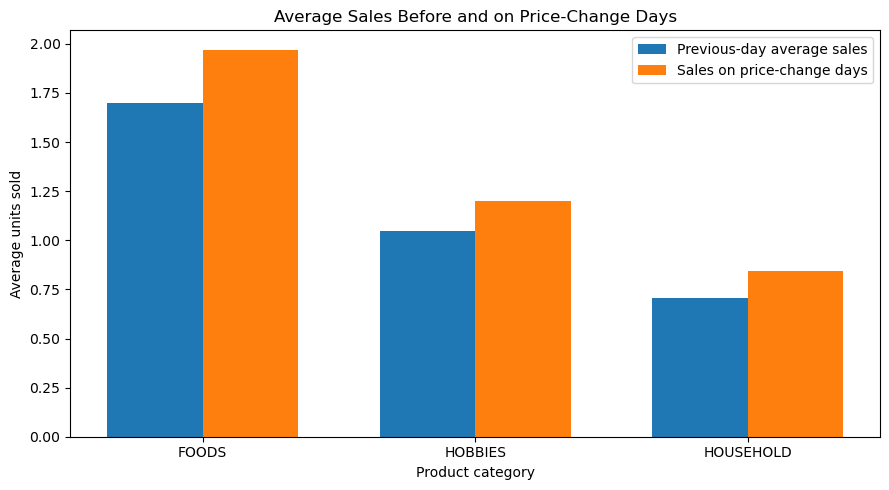

In [68]:
import matplotlib.pyplot as plt
import numpy as np

categories = category_price_analysis["cat_id"]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    category_price_analysis["average_previous_sales"],
    width,
    label="Previous-day average sales"
)

plt.bar(
    x + width / 2,
    category_price_analysis["average_sales"],
    width,
    label="Sales on price-change days"
)

plt.xticks(x, categories)
plt.xlabel("Product category")
plt.ylabel("Average units sold")
plt.title("Average Sales Before and on Price-Change Days")
plt.legend()
plt.tight_layout()
plt.savefig("avg_sale_before_after.png", dpi= 800, bbox_inches="tight")
plt.show()

# DAY 5

## Fair Model Evaluation and Comparison 

#### Find out whether adding price features actually improves our forecasting models.

### Checking our current notebook state

In [69]:
# DAY 5 — Step 1: Inspect our current modeling state

print("=" * 55)
print("DATASET STATUS")
print("=" * 55)

for name in ["train_model", "test_model", "train_df", "test_df"]:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {obj.shape}")
    else:
        print(f"{name}: NOT FOUND")


print("\n" + "=" * 55)
print("FEATURE STATUS")
print("=" * 55)

for name in ["base_features", "price_features"]:
    if name in globals():
        print(f"{name}: {globals()[name]}")
    else:
        print(f"{name}: NOT FOUND")


print("\n" + "=" * 55)
print("TRAINED MODEL STATUS")
print("=" * 55)

for name in [
    "rf_model",
    "lgb_model",
    "lr_model",
    "rf_price",
    "lgb_price",
    "lr_price"
]:
    if name in globals():
        print(f"{name}: AVAILABLE")
    else:
        print(f"{name}: NOT FOUND")


print("\n" + "=" * 55)
print("PREDICTION STATUS")
print("=" * 55)

for name in [
    "lr_predictions",
    "rf_predictions",
    "lgb_predictions",
    "lr_price_predictions",
    "rf_price_predictions",
    "lgb_price_predictions"
]:
    if name in globals():
        print(f"{name}: {len(globals()[name]):,} predictions")
    else:
        print(f"{name}: NOT FOUND")

DATASET STATUS
train_model: (1502000, 36)
test_model: (383000, 36)
train_df: (1530000, 36)
test_df: (383000, 36)

FEATURE STATUS
base_features: ['lag_1', 'lag_7', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'day_of_week', 'month', 'is_event', 'snap_CA', 'snap_TX', 'snap_WI']
price_features: ['sell_price_imputed', 'log_price_change_imputed', 'price_changed', 'price_missing']

TRAINED MODEL STATUS
rf_model: AVAILABLE
lgb_model: AVAILABLE
lr_model: AVAILABLE
rf_price: AVAILABLE
lgb_price: AVAILABLE
lr_price: AVAILABLE

PREDICTION STATUS
lr_predictions: 28,000 predictions
rf_predictions: 28,000 predictions
lgb_predictions: 28,000 predictions
lr_price_predictions: 383,000 predictions
rf_price_predictions: 383,000 predictions
lgb_price_predictions: 383,000 predictions


### Fair Model comparision

In [70]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# DAY 5 — Fair comparison on the same test observations

# Define feature sets
base_features = base_features
all_features = base_features + price_features

# Actual sales
y_actual = test_model["sales"].to_numpy()

# Generate predictions on the SAME chronological test dataset
# Baseline models: demand and calendar features only
baseline_predictions = {
    "Linear Regression": lr_model.predict(test_model[base_features]),
    "Random Forest": rf_model.predict(test_model[base_features]),
    "LightGBM": lgb_model.predict(test_model[base_features])
}

# Price-aware models: demand, calendar, and price features
price_predictions = {
    "Linear Regression + Price": lr_price.predict(test_model[all_features]),
    "Random Forest + Price": rf_price.predict(test_model[all_features]),
    "LightGBM + Price": lgb_price.predict(test_model[all_features])
}

# Calculate consistent metrics
def calculate_wape(actual, predicted):
    denominator = np.abs(actual).sum()
    if denominator == 0:
        return np.nan
    return np.abs(actual - predicted).sum() / denominator * 100

results = []

for model_name, predictions in {
    **baseline_predictions,
    **price_predictions
}.items():

    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_actual, predictions),
        "WAPE (%)": calculate_wape(y_actual, predictions)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="WAPE (%)",
    ascending=True
).reset_index(drop=True)

print("MODEL COMPARISON — SAME CHRONOLOGICAL TEST SET")
print(f"Test observations: {len(y_actual):,}")
display(comparison_df.round(4))

MODEL COMPARISON — SAME CHRONOLOGICAL TEST SET
Test observations: 383,000


,Model,MAE,WAPE (%)
0,Random Forest,0.8645,74.4703
1,LightGBM,0.8751,75.3841
2,Random Forest + Price,0.8845,76.1945
3,LightGBM + Price,0.8852,76.2543
4,Linear Regression,0.9070,78.1321
5,Linear Regression + Price,0.9113,78.5023


### Key Finding :- adding price features made every model slightly worse, not better.

## This Seems Strange

##### The reported training dataset has 1,502,000 rows, while train_df has 1,530,000 rows. That difference may result from filtering missing feature values, but we should verify the actual training setup before claiming that adding price features alone caused the performance difference.

### Verify training observations :- The reported training dataset has 1,502,000 rows, while train_df has 1,530,000 rows

In [71]:
# DAY 5 — Step 3: Verify training and test dataset alignment

print("=" * 55)
print("TRAINING AND TESTING DATA")
print("=" * 55)

print(f"train_df rows:     {len(train_df):,}")
print(f"train_model rows:  {len(train_model):,}")
print(f"test_df rows:      {len(test_df):,}")
print(f"test_model rows:   {len(test_model):,}")

print("\n" + "=" * 55)
print("MODEL TRAINING OBSERVATIONS")
print("=" * 55)

for name in ["rf_model", "lgb_model", "lr_model",
             "rf_price", "lgb_price", "lr_price"]:

    model = globals()[name]

    if hasattr(model, "n_features_in_"):
        print(f"{name}: {model.n_features_in_} input features")

    if hasattr(model, "n_samples_seen_"):
        print(f"{name}: {model.n_samples_seen_} samples seen")

print("\n" + "=" * 55)
print("FEATURE COUNTS")
print("=" * 55)

print(f"Baseline features: {len(base_features)}")
print(f"Price features:    {len(price_features)}")
print(f"Combined features: {len(base_features) + len(price_features)}")

TRAINING AND TESTING DATA
train_df rows:     1,530,000
train_model rows:  1,502,000
test_df rows:      383,000
test_model rows:   383,000

MODEL TRAINING OBSERVATIONS
rf_model: 11 input features
lgb_model: 11 input features
lr_model: 11 input features
rf_price: 15 input features
lgb_price: 15 input features
lr_price: 15 input features

FEATURE COUNTS
Baseline features: 11
Price features:    4
Combined features: 15


### Invegtigate the 28000 excluded rows 

In [72]:
# Investigate rows excluded from model training

print("TRAINING DATA ROW AUDIT")
print("-" * 50)

print(f"Original training rows: {len(train_df):,}")
print(f"Rows used for training: {len(train_model):,}")
print(f"Rows excluded:          {len(train_df) - len(train_model):,}")

print("\nMissing values in original training data:")

columns_to_check = base_features + ["sales"]

missing_counts = train_df[columns_to_check].isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

if missing_counts.empty:
    print("No missing values in baseline features or target.")
else:
    print(missing_counts)

print("\nRows with any missing baseline feature or target:")
rows_with_missing = train_df[columns_to_check].isna().any(axis=1)
print(f"{rows_with_missing.sum():,}")

TRAINING DATA ROW AUDIT
--------------------------------------------------
Original training rows: 1,530,000
Rows used for training: 1,502,000
Rows excluded:          28,000

Missing values in original training data:
lag_28             28000
rolling_mean_28    28000
lag_7               7000
rolling_mean_7      7000
lag_1               1000
dtype: int64

Rows with any missing baseline feature or target:
28,000


### Verify training Allignment

In [73]:
# Check whether baseline and price-aware models used the same training rows

print("TRAINING ALIGNMENT CHECK")
print("-" * 50)

print(f"train_model rows: {len(train_model):,}")
print(f"train_df rows:    {len(train_df):,}")

# Check missing values in price-aware training features
price_model_features = base_features + price_features

print("\nMissing values in price-aware training features:")
print(
    train_df[price_model_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Compare the indices of the baseline and price-aware training datasets
print("\nIndex comparison:")

if "price_train_model" in globals():
    print(
        "Same training indices:",
        train_model.index.equals(price_train_model.index)
    )
    print(f"Price training rows: {len(price_train_model):,}")
else:
    print(
        "No separate price_train_model variable found. "
        "We will inspect the existing model-training cell to verify alignment."
    )

TRAINING ALIGNMENT CHECK
--------------------------------------------------
train_model rows: 1,502,000
train_df rows:    1,530,000

Missing values in price-aware training features:
lag_28             28000
rolling_mean_28    28000
lag_7               7000
rolling_mean_7      7000
lag_1               1000
day_of_week            0
month                  0
is_event               0
snap_CA                0
snap_TX                0
dtype: int64

Index comparison:
No separate price_train_model variable found. We will inspect the existing model-training cell to verify alignment.


In [74]:
print("BASELINE TRAINING DATA")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nPRICE MODEL TRAINING DATA")
print("X_train_price:", X_train_price.shape)
print("y_train:", y_train.shape)

print("\nBASELINE TEST DATA")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nPRICE MODEL TEST DATA")
print("X_test_price:", X_test_price.shape)
print("y_test:", y_test.shape)

BASELINE TRAINING DATA
X_train: (1857000, 11)
y_train: (1502000,)

PRICE MODEL TRAINING DATA
X_train_price: (1502000, 15)
y_train: (1502000,)

BASELINE TEST DATA
X_test: (28000, 11)
y_test: (383000,)

PRICE MODEL TEST DATA
X_test_price: (383000, 15)
y_test: (383000,)


## GOT A ISSUE 

### We found the problem. Our current model comparison is not valid yet because the baseline and price-aware models have different training and test datasets.


### There are two issues:

#### X_train has 1,857,000 rows, while y_train has only 1,502,000. These cannot be passed together to .fit(), so the displayed variables have been overwritten or come from different stages.
#### X_test has only 28,000 rows, but y_test has 383,000. Therefore, the old baseline test matrix doesn't match the current evaluation set.

In [75]:
# Rebuild baseline matrices using the same rows as the price models

X_train_base = train_model[base_features].copy()
y_train_base = train_model[target].copy()

X_test_base = test_model[base_features].copy()
y_test_base = test_model[target].copy()

print("Baseline training:", X_train_base.shape, y_train_base.shape)
print("Baseline testing:", X_test_base.shape, y_test_base.shape)

print("\nPrice-model training:", X_train_price.shape, y_train.shape)
print("Price-model testing:", X_test_price.shape, y_test.shape)

Baseline training: (1502000, 11) (1502000,)
Baseline testing: (383000, 11) (383000,)

Price-model training: (1502000, 15) (1502000,)
Price-model testing: (383000, 15) (383000,)


### Retraining the baseline models

In [76]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import lightgbm as lgb
import numpy as np

# 1. Random Forest
print("Training Random Forest...")
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_base, y_train_base)

rf_predictions = np.maximum(rf_model.predict(X_test_base), 0)


# 2. LightGBM
print("Training LightGBM...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)
lgb_model.fit(X_train_base, y_train_base)

lgb_predictions = np.maximum(lgb_model.predict(X_test_base), 0)


# 3. Linear Regression
print("Training Linear Regression...")
lr_model = LinearRegression()
lr_model.fit(X_train_base, y_train_base)

lr_predictions = np.maximum(lr_model.predict(X_test_base), 0)


print("\nAll three baseline models trained successfully!")
print("Training rows:", len(y_train_base))
print("Testing rows:", len(y_test_base))

Training Random Forest...
Training LightGBM...
Training Linear Regression...

All three baseline models trained successfully!
Training rows: 1502000
Testing rows: 383000


### MODEL EVALUATION AND COMPARISON RETURNS...

In [77]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# Actual test values
y_actual = y_test_base.to_numpy()

# Predictions from all six models, clipped at zero
all_predictions = {
    "Random Forest": np.maximum(rf_model.predict(X_test_base), 0),
    "LightGBM": np.maximum(lgb_model.predict(X_test_base), 0),
    "Linear Regression": np.maximum(lr_model.predict(X_test_base), 0),
    "Random Forest + Price": np.maximum(rf_price.predict(X_test_price), 0),
    "LightGBM + Price": np.maximum(lgb_price.predict(X_test_price), 0),
    "Linear Regression + Price": np.maximum(lr_price.predict(X_test_price), 0)
}

# Calculate metrics
results = []

for model_name, predictions in all_predictions.items():
    mae = mean_absolute_error(y_actual, predictions)
    wape = (
        np.abs(y_actual - predictions).sum()
        / np.abs(y_actual).sum()
    ) * 100

    results.append({
        "Model": model_name,
        "MAE": round(mae, 4),
        "WAPE (%)": round(wape, 2)
    })

results_df = pd.DataFrame(results).sort_values("WAPE (%)")

print("FAIR MODEL COMPARISON")
print("Test observations:", len(y_actual))
display(results_df.reset_index(drop=True))

FAIR MODEL COMPARISON
Test observations: 383000


,Model,MAE,WAPE (%)
0,Random Forest,0.8817,75.95
1,LightGBM,0.8838,76.13
2,Random Forest + Price,0.8845,76.19
3,LightGBM + Price,0.8851,76.25
4,Linear Regression,0.9029,77.77
5,Linear Regression + Price,0.9078,78.19


## Random Forest is our current winner , but selected model for project is lightGBM so we will go ahead with it , while keeping the Random Forest as our benchmark

### Price features did not improve accuracy

## Save the comparison results

In [78]:
import os
import pandas as pd

# Create results directory if it doesn't exist
os.makedirs("../reports", exist_ok=True)

# Save model comparison
results_df = results_df.sort_values("WAPE (%)").reset_index(drop=True)

results_df.to_csv(
    "../reports/day5_model_comparison.csv",
    index=False
)

print("Day 5 model comparison saved successfully!")
print("../reports/day5_model_comparison.csv")

Day 5 model comparison saved successfully!
../reports/day5_model_comparison.csv


# Day 6

# Forecast error Analysis

#####  A model can have an acceptable overall error score while consistently underpredicting demand for certain products, potentially increasing stockout risk.

### Generate LightGBM predictions

In [79]:
# Generate predictions using our selected LightGBM model

lgb_final_predictions = np.maximum(
    lgb_model.predict(X_test_base),
    0
)

# Create an error analysis dataframe
error_df = test_model[[
    "id", "item_id", "store_id", "sales", "date"
]].copy()

error_df["actual_sales"] = y_test_base.to_numpy()
error_df["predicted_sales"] = lgb_final_predictions

error_df["absolute_error"] = np.abs(
    error_df["actual_sales"] - error_df["predicted_sales"]
)

error_df["error"] = (
    error_df["actual_sales"] - error_df["predicted_sales"]
)

print("Error analysis dataset created!")
print("Shape:", error_df.shape)

display(error_df.head())

Error analysis dataset created!
Shape: (383000, 9)


,id,item_id,store_id,sales,date,actual_sales,predicted_sales,absolute_error,error
1530,FOODS_1_003_TX_3_validation,FOODS_1_003,TX_3,0,2015-04-08,0,0.009665,0.009665,-0.009665
3443,FOODS_1_005_CA_1_validation,FOODS_1_005,CA_1,0,2015-04-08,0,0.321016,0.321016,-0.321016
5356,FOODS_1_005_TX_1_validation,FOODS_1_005,TX_1,0,2015-04-08,0,0.009665,0.009665,-0.009665
7269,FOODS_1_005_TX_3_validation,FOODS_1_005,TX_3,1,2015-04-08,1,0.541654,0.458346,0.458346
9182,FOODS_1_008_CA_2_validation,FOODS_1_008,CA_2,1,2015-04-08,1,0.349109,0.650891,0.650891


### Analyze the error Distribution

In [80]:
# Overall forecasting error statistics

print("OVERALL ERROR ANALYSIS")
print("-" * 40)

print("Mean Absolute Error:", round(error_df["absolute_error"].mean(), 4))
print("Median Absolute Error:", round(error_df["absolute_error"].median(), 4))
print("Maximum Absolute Error:", round(error_df["absolute_error"].max(), 4))

print("\nERROR DIRECTION")
print("-" * 40)

overpredictions = (error_df["error"] < 0).sum()
underpredictions = (error_df["error"] > 0).sum()
exact_predictions = (error_df["error"] == 0).sum()

print("Overpredictions:", overpredictions)
print("Underpredictions:", underpredictions)
print("Exact predictions:", exact_predictions)

print("\nERROR DIRECTION (%)")
print("Overpredictions:", round(overpredictions / len(error_df) * 100, 2), "%")
print("Underpredictions:", round(underpredictions / len(error_df) * 100, 2), "%")
print("Exact predictions:", round(exact_predictions / len(error_df) * 100, 2), "%")

OVERALL ERROR ANALYSIS
----------------------------------------
Mean Absolute Error: 0.8838
Median Absolute Error: 0.4652
Maximum Absolute Error: 92.0

ERROR DIRECTION
----------------------------------------
Overpredictions: 263826
Underpredictions: 110974
Exact predictions: 8200

ERROR DIRECTION (%)
Overpredictions: 68.88 %
Underpredictions: 28.97 %
Exact predictions: 2.14 %


### Find the 10 largest Forecasting errors

In [81]:
# Find the 10 observations with the largest absolute errors

largest_errors = (
    error_df
    .sort_values("absolute_error", ascending=False)
    [[
        "date",
        "item_id",
        "store_id",
        "actual_sales",
        "predicted_sales",
        "absolute_error",
        "error"
    ]]
    .head(10)
    .reset_index(drop=True)
)

print("TOP 10 LARGEST FORECASTING ERRORS")
display(largest_errors)

TOP 10 LARGEST FORECASTING ERRORS


,date,item_id,store_id,actual_sales,predicted_sales,absolute_error,error
0,2016-02-10,FOODS_3_318,WI_3,92,0.000000,92.000000,92.000000
1,2015-06-12,FOODS_3_723,CA_3,88,16.042447,71.957553,71.957553
2,2015-08-15,FOODS_3_008,CA_2,73,11.104489,61.895511,61.895511
3,2015-06-07,FOODS_3_319,TX_1,50,0.364122,49.635878,49.635878
4,2015-04-16,FOODS_3_234,CA_4,52,3.793365,48.206635,48.206635
5,2015-09-13,FOODS_3_288,CA_2,73,24.858173,48.141827,48.141827
6,2015-06-11,FOODS_3_723,CA_3,48,0.075220,47.924780,47.924780
7,2016-01-22,HOBBIES_1_387,CA_2,50,2.950711,47.049289,47.049289
8,2015-07-27,HOBBIES_1_178,CA_4,49,3.354241,45.645759,45.645759
9,2016-01-16,HOBBIES_1_178,CA_4,51,6.108058,44.891942,44.891942


### Investigate the worst errors

In [82]:
# Analyze the largest errors by item and store

top_errors = error_df.nlargest(100, "absolute_error")

print("Top 100 errors by store:")
display(
    top_errors.groupby("store_id")
    .agg(
        error_count=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        max_absolute_error=("absolute_error", "max")
    )
    .sort_values("error_count", ascending=False)
)

print("\nTop 100 errors by item:")
display(
    top_errors.groupby("item_id")
    .agg(
        error_count=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        max_absolute_error=("absolute_error", "max")
    )
    .sort_values("error_count", ascending=False)
    .head(10)
)

Top 100 errors by store:


,error_count,mean_absolute_error,max_absolute_error
store_id,,,
CA_3,30,33.795197,71.957553
CA_2,25,34.247468,61.895511
CA_4,20,35.072005,48.206635
WI_2,10,32.809131,43.274366
WI_3,7,41.350722,92.000000
TX_3,3,31.314400,33.107954
TX_2,3,35.969324,40.850970
TX_1,2,39.094954,49.635878



Top 100 errors by item:


,error_count,mean_absolute_error,max_absolute_error
item_id,,,
FOODS_3_723,18,36.000165,71.957553
HOUSEHOLD_1_465,10,32.809131,43.274366
FOODS_3_008,9,33.579262,61.895511
HOBBIES_1_178,9,38.870031,45.645759
FOODS_3_288,7,34.658169,48.141827
HOBBIES_1_295,5,29.417701,30.705426
HOBBIES_1_387,5,34.706519,47.049289
FOODS_3_234,4,35.511930,48.206635
FOODS_3_318,4,49.473570,92.000000


### Analyze error by item 

In [83]:
# Analyze the 10 items appearing most frequently
# among the 100 largest forecasting errors

top_100_errors = error_df.nlargest(100, "absolute_error")

item_error_analysis = (
    top_100_errors
    .groupby("item_id")
    .agg(
        error_count=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        max_absolute_error=("absolute_error", "max"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum")
    )
    .sort_values(
        ["error_count", "mean_absolute_error"],
        ascending=False
    )
    .head(10)
)

display(item_error_analysis)

,error_count,mean_absolute_error,max_absolute_error,total_actual_sales,total_predicted_sales
item_id,,,,,
FOODS_3_723,18,36.000165,71.957553,904,474.957348
HOUSEHOLD_1_465,10,32.809131,43.274366,452,123.908691
HOBBIES_1_178,9,38.870031,45.645759,407,57.169722
FOODS_3_008,9,33.579262,61.895511,439,191.446133
FOODS_3_288,7,34.658169,48.141827,369,193.760894
HOBBIES_1_387,5,34.706519,47.049289,203,29.467406
HOBBIES_1_295,5,29.417701,30.705426,173,25.911496
FOODS_3_318,4,49.473570,92.000000,205,62.162988
FOODS_3_234,4,35.511930,48.206635,124,44.146956


### Analyze  error by actual sales

In [84]:
import pandas as pd
import numpy as np

# Group actual sales into demand levels
error_df["demand_level"] = pd.cut(
    error_df["actual_sales"],
    bins=[-1, 0, 1, 5, 10, float("inf")],
    labels=[
        "Zero sales",
        "1 unit",
        "2–5 units",
        "6–10 units",
        "Above 10 units"
    ]
)

# Compare actual and predicted sales by demand level
demand_error_analysis = (
    error_df.groupby("demand_level", observed=False)
    .agg(
        observations=("actual_sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        average_absolute_error=("absolute_error", "mean"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum")
    )
    .reset_index()
)

demand_error_analysis = demand_error_analysis.round(3)

display(demand_error_analysis)

,demand_level,observations,average_actual_sales,average_predicted_sales,average_absolute_error,total_actual_sales,total_predicted_sales
0,Zero sales,231349,0.000,0.505,0.505,0,116745.801
1,1 unit,68502,1.000,0.977,0.626,68502,66959.773
2,2–5 units,66099,2.831,1.997,1.475,187094,132002.902
3,6–10 units,11177,7.374,5.079,3.328,82418,56770.019
4,Above 10 units,5873,18.153,12.301,7.518,106612,72243.613


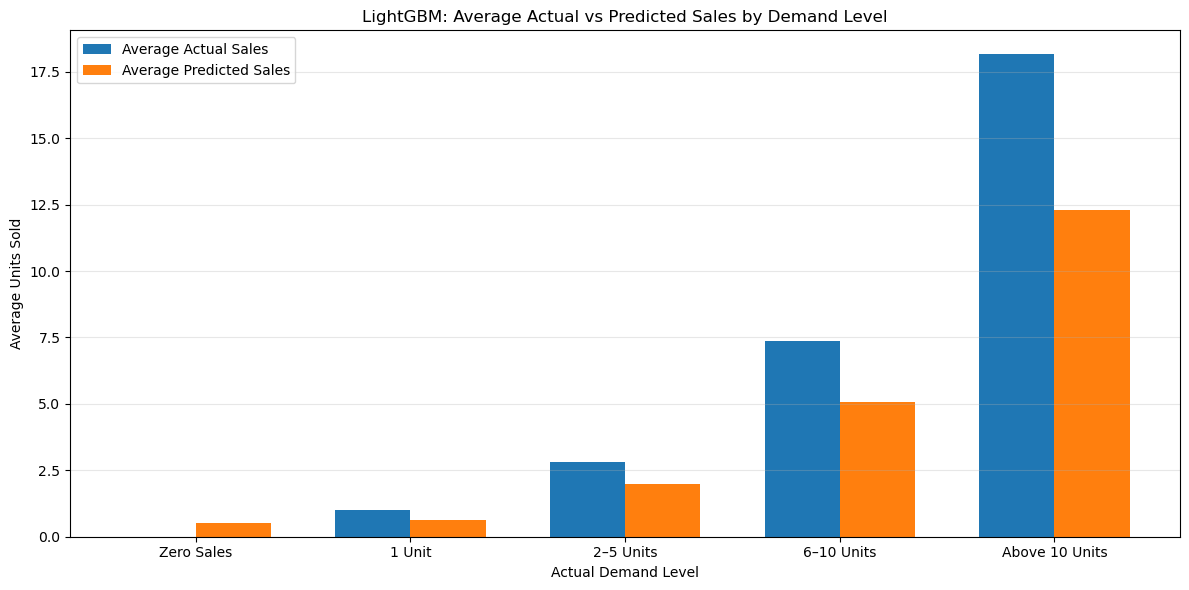

In [85]:
import matplotlib.pyplot as plt
import numpy as np

# Demand-level analysis
demand_labels = [
    "Zero Sales",
    "1 Unit",
    "2–5 Units",
    "6–10 Units",
    "Above 10 Units"
]

actual_sales = [0.000, 1.000, 2.831, 7.374, 18.153]
predicted_sales = [0.505, 0.626, 1.997, 5.079, 12.301]

x = np.arange(len(demand_labels))
width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    actual_sales,
    width,
    label="Average Actual Sales"
)

plt.bar(
    x + width / 2,
    predicted_sales,
    width,
    label="Average Predicted Sales"
)

plt.xticks(x, demand_labels)
plt.xlabel("Actual Demand Level")
plt.ylabel("Average Units Sold")
plt.title("LightGBM: Average Actual vs Predicted Sales by Demand Level")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "lightgbm_actual_vs_predicted_by_demand.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

###### The model tends to underpredict average sales in the higher-demand groups

### Actual Sales 

In [87]:
item = "FOODS_3_723"
store = "CA_3"

item_data = error_df[
    (error_df["item_id"] == item) &
    (error_df["store_id"] == store)
].copy()

item_data["date"] = pd.to_datetime(item_data["date"])

item_data = item_data.sort_values("date").reset_index(drop=True)

print(item_data.shape)
item_data.head()

(383, 10)


,id,item_id,store_id,sales,date,actual_sales,predicted_sales,absolute_error,error,demand_level
0,FOODS_3_723_CA_3_validation,FOODS_3_723,CA_3,24,2015-04-08,24,12.915446,11.084554,11.084554,Above 10 units
1,FOODS_3_723_CA_3_validation,FOODS_3_723,CA_3,18,2015-04-09,18,18.203369,0.203369,-0.203369,Above 10 units
2,FOODS_3_723_CA_3_validation,FOODS_3_723,CA_3,28,2015-04-10,28,17.950353,10.049647,10.049647,Above 10 units
3,FOODS_3_723_CA_3_validation,FOODS_3_723,CA_3,15,2015-04-11,15,21.543404,6.543404,-6.543404,Above 10 units
4,FOODS_3_723_CA_3_validation,FOODS_3_723,CA_3,49,2015-04-12,49,19.182878,29.817122,29.817122,Above 10 units


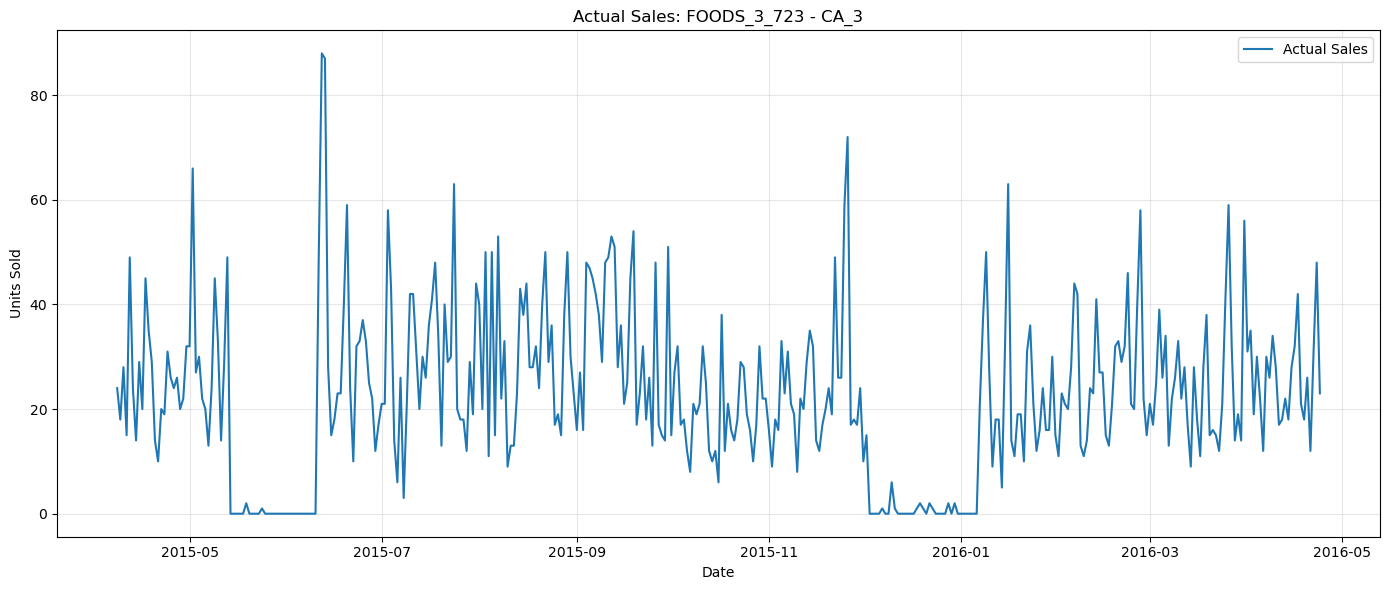

In [88]:
plt.figure(figsize=(14, 6))

plt.plot(
    item_data["date"],
    item_data["actual_sales"],
    label="Actual Sales",
    linewidth=1.5
)

plt.title("Actual Sales: FOODS_3_723 - CA_3")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize actual vs Preddicted Sales

Number of test observations: 383
Total actual sales: 8600
Total predicted sales: 8378.181922349053


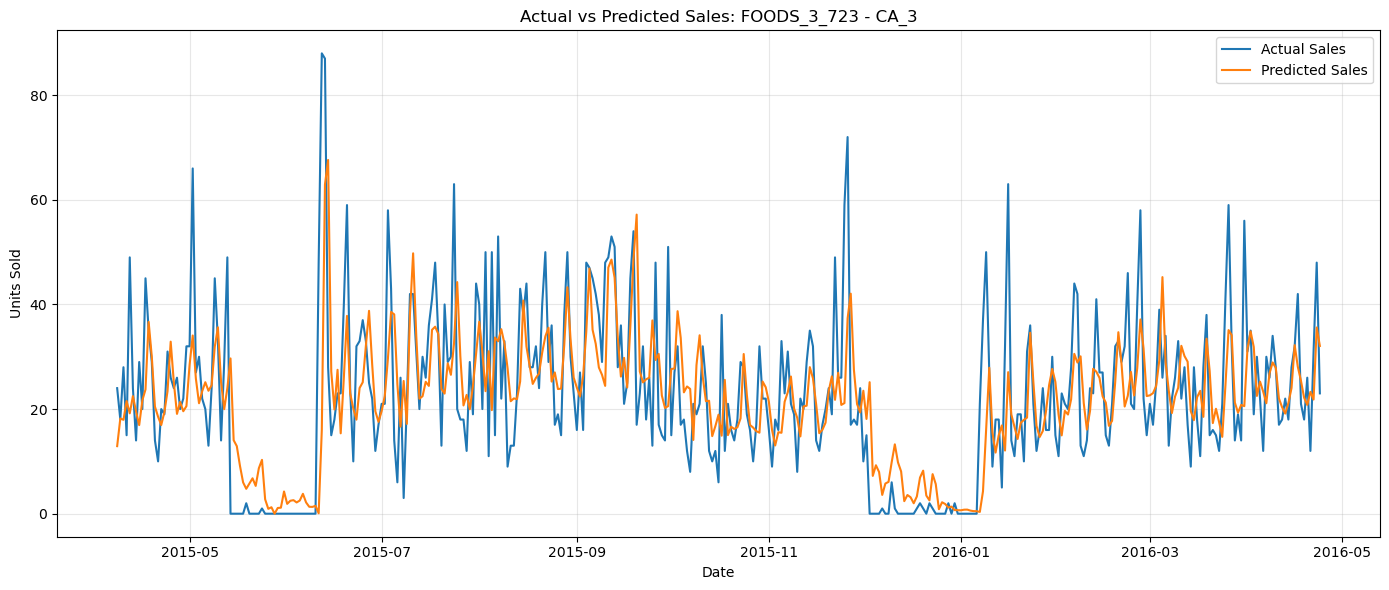

In [89]:
import matplotlib.pyplot as plt
import pandas as pd

# Select one item-store combination
item_id = "FOODS_3_723"
store_id = "CA_3"

item_data = error_df[
    (error_df["item_id"] == item_id) &
    (error_df["store_id"] == store_id)
].copy()

item_data["date"] = pd.to_datetime(item_data["date"])
item_data = item_data.sort_values("date")

print("Number of test observations:", len(item_data))
print("Total actual sales:", item_data["actual_sales"].sum())
print("Total predicted sales:", item_data["predicted_sales"].sum())

plt.figure(figsize=(14, 6))

plt.plot(
    item_data["date"],
    item_data["actual_sales"],
    label="Actual Sales",
    linewidth=1.5
)

plt.plot(
    item_data["date"],
    item_data["predicted_sales"],
    label="Predicted Sales",
    linewidth=1.5
)

plt.title(f"Actual vs Predicted Sales: {item_id} - {store_id}")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Evaluate Model performance by store 

In [90]:
# Calculate forecasting performance for every store

store_performance = (
    error_df.groupby("store_id")
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_absolute_error=("absolute_error", "sum"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

store_performance["WAPE"] = (
    store_performance["total_absolute_error"]
    / store_performance["total_actual_sales"].replace(0, np.nan)
) * 100

store_performance = store_performance.sort_values(
    "WAPE", ascending=False
)

display(
    store_performance[
        ["store_id", "observations", "MAE", "WAPE"]
    ].round(2)
)

,store_id,observations,MAE,WAPE
3,CA_4,44428,0.73,96.44
4,TX_1,49024,0.73,86.48
7,WI_1,34470,0.82,82.17
5,TX_2,34087,0.83,80.30
6,TX_3,33704,0.81,76.97
8,WI_2,38300,0.92,76.73
9,WI_3,37534,0.76,75.20
1,CA_2,42130,1.08,70.53
0,CA_1,31406,0.98,70.31
2,CA_3,37917,1.23,64.16


### Visualize store-level WAPE

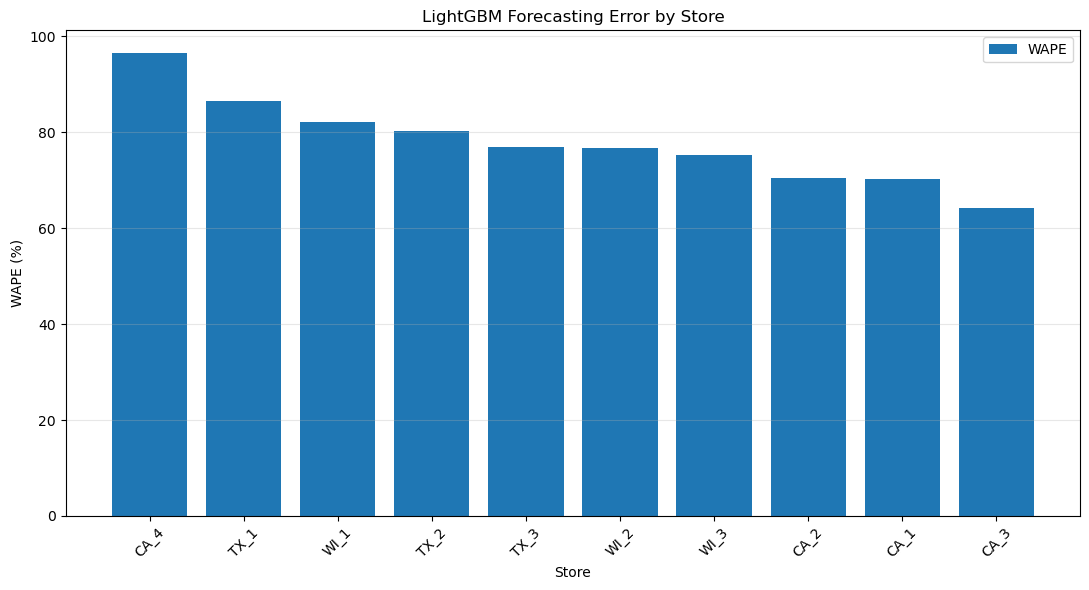

In [91]:
import matplotlib.pyplot as plt

plot_df = store_performance.sort_values("WAPE", ascending=False)

plt.figure(figsize=(11, 6))

plt.bar(
    plot_df["store_id"],
    plot_df["WAPE"],
    label="WAPE"
)

plt.title("LightGBM Forecasting Error by Store")
plt.xlabel("Store")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    "lightgbm_store_level_wape.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Investigate High-error Stores

In [92]:
# Compare actual vs predicted sales for the two highest-WAPE stores

high_error_stores = ["CA_4", "TX_1"]

store_demand_analysis = (
    error_df[error_df["store_id"].isin(high_error_stores)]
    .assign(
        demand_level=pd.cut(
            error_df.loc[
                error_df["store_id"].isin(high_error_stores),
                "actual_sales"
            ],
            bins=[-1, 0, 1, 5, 10, float("inf")],
            labels=[
                "Zero sales",
                "1 unit",
                "2–5 units",
                "6–10 units",
                "Above 10 units"
            ]
        ).values
    )
    .groupby(["store_id", "demand_level"], observed=False)
    .agg(
        observations=("actual_sales", "size"),
        average_actual=("actual_sales", "mean"),
        average_predicted=("predicted_sales", "mean"),
        MAE=("absolute_error", "mean"),
        total_actual=("actual_sales", "sum"),
        total_absolute_error=("absolute_error", "sum")
    )
    .reset_index()
)

store_demand_analysis["WAPE"] = (
    store_demand_analysis["total_absolute_error"]
    / store_demand_analysis["total_actual"].replace(0, float("nan"))
    * 100
)

store_demand_analysis.round(3)

,store_id,demand_level,observations,average_actual,average_predicted,MAE,total_actual,total_absolute_error,WAPE
0,CA_4,Zero sales,30102,0.000,0.437,0.437,0,13168.212,NaN
1,CA_4,1 unit,7531,1.000,0.830,0.584,7531,4399.384,58.417
2,CA_4,2–5 units,5770,2.750,1.776,1.560,15870,9002.907,56.729
3,CA_4,6–10 units,750,7.268,4.041,3.460,5451,2594.865,47.603
4,CA_4,Above 10 units,275,17.742,5.533,12.230,4879,3363.235,68.933
5,TX_1,Zero sales,32804,0.000,0.432,0.432,0,14170.523,NaN
6,TX_1,1 unit,8320,1.000,0.805,0.622,8320,5174.816,62.197
7,TX_1,2–5 units,6391,2.764,1.717,1.502,17664,9599.376,54.344
8,TX_1,6–10 units,1033,7.393,4.835,3.701,7637,3822.866,50.057
9,TX_1,Above 10 units,476,15.786,10.737,5.896,7514,2806.277,37.347


### Visualize Store-Level Demand Errors

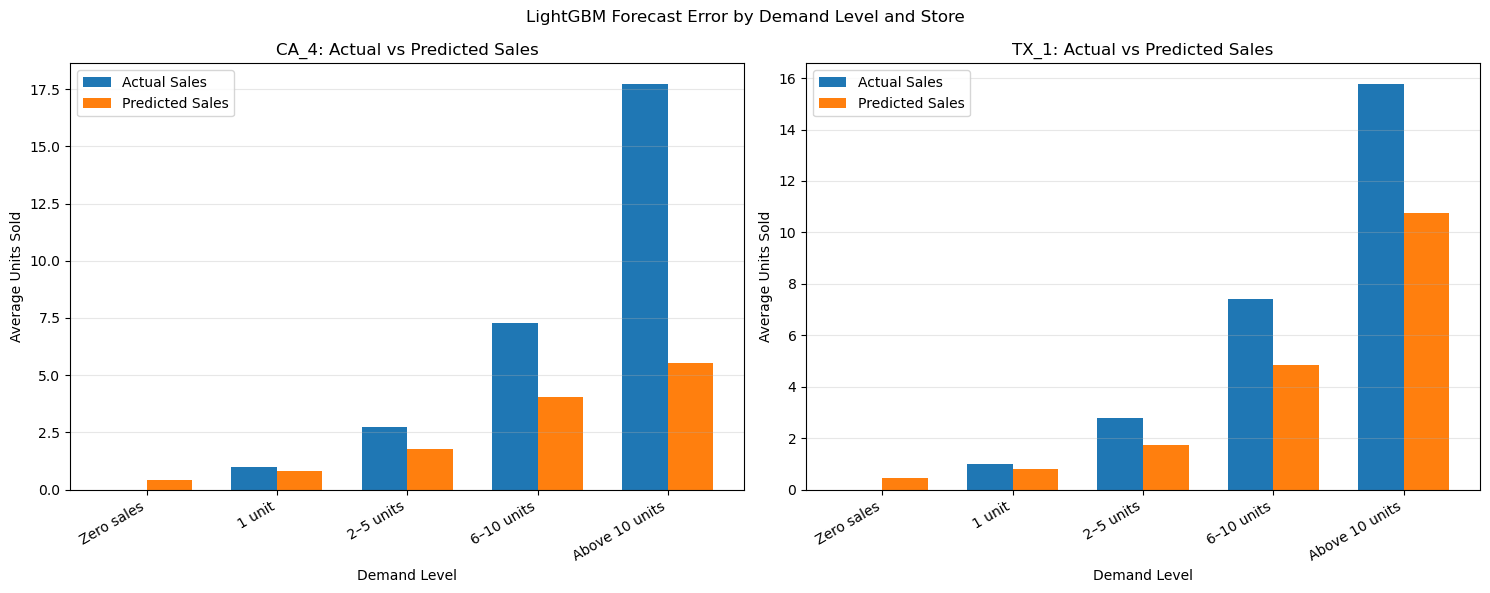

In [93]:
import matplotlib.pyplot as plt
import numpy as np

demand_levels = [
    "Zero sales",
    "1 unit",
    "2–5 units",
    "6–10 units",
    "Above 10 units"
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, store in zip(axes, ["CA_4", "TX_1"]):
    plot_data = (
        store_demand_analysis[
            store_demand_analysis["store_id"] == store
        ]
        .set_index("demand_level")
        .reindex(demand_levels)
    )

    x = np.arange(len(demand_levels))
    width = 0.35

    ax.bar(
        x - width / 2,
        plot_data["average_actual"],
        width,
        label="Actual Sales"
    )

    ax.bar(
        x + width / 2,
        plot_data["average_predicted"],
        width,
        label="Predicted Sales"
    )

    ax.set_title(f"{store}: Actual vs Predicted Sales")
    ax.set_xlabel("Demand Level")
    ax.set_ylabel("Average Units Sold")
    ax.set_xticks(x)
    ax.set_xticklabels(demand_levels, rotation=30, ha="right")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("LightGBM Forecast Error by Demand Level and Store")
plt.tight_layout()

plt.savefig(
    "lightgbm_high_error_stores_demand_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Quantify the Underprediction 

In [94]:
# Quantify underprediction by store and demand level

store_demand_analysis["prediction_gap"] = (
    store_demand_analysis["average_actual"]
    - store_demand_analysis["average_predicted"]
)

store_demand_analysis["underprediction_pct"] = np.where(
    store_demand_analysis["average_actual"] > 0,
    (
        store_demand_analysis["prediction_gap"]
        / store_demand_analysis["average_actual"]
    ) * 100,
    np.nan
)

store_demand_analysis[
    [
        "store_id",
        "demand_level",
        "observations",
        "average_actual",
        "average_predicted",
        "prediction_gap",
        "underprediction_pct"
    ]
].round(2)

,store_id,demand_level,observations,average_actual,average_predicted,prediction_gap,underprediction_pct
0,CA_4,Zero sales,30102,0.00,0.44,-0.44,NaN
1,CA_4,1 unit,7531,1.00,0.83,0.17,17.05
2,CA_4,2–5 units,5770,2.75,1.78,0.97,35.41
3,CA_4,6–10 units,750,7.27,4.04,3.23,44.40
4,CA_4,Above 10 units,275,17.74,5.53,12.21,68.81
5,TX_1,Zero sales,32804,0.00,0.43,-0.43,NaN
6,TX_1,1 unit,8320,1.00,0.80,0.20,19.53
7,TX_1,2–5 units,6391,2.76,1.72,1.05,37.89
8,TX_1,6–10 units,1033,7.39,4.83,2.56,34.60
9,TX_1,Above 10 units,476,15.79,10.74,5.05,31.98


### Identify the Worst-forecast items

In [95]:
# Identify items with the largest forecasting errors in CA_4 and TX_1

high_error_items = (
    error_df[error_df["store_id"].isin(["CA_4", "TX_1"])]
    .groupby(["store_id", "item_id"])
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        MAE=("absolute_error", "mean"),
        total_absolute_error=("absolute_error", "sum")
    )
    .reset_index()
)

high_error_items["WAPE"] = (
    high_error_items["total_absolute_error"]
    / high_error_items["total_actual_sales"].replace(0, np.nan)
    * 100
)

worst_items_by_store = (
    high_error_items
    .sort_values(
        ["store_id", "total_absolute_error"],
        ascending=[True, False]
    )
    .groupby("store_id")
    .head(10)
)

worst_items_by_store.round(3)

,store_id,item_id,observations,total_actual_sales,total_predicted_sales,MAE,total_absolute_error,WAPE
62,CA_4,HOBBIES_1_178,383,2500,2336.741,6.216,2380.560,95.222
67,CA_4,HOBBIES_1_295,383,2397,2302.209,4.565,1748.214,72.933
58,CA_4,HOBBIES_1_008,383,1936,1869.568,4.071,1559.053,80.530
66,CA_4,HOBBIES_1_288,383,1717,1669.944,3.747,1435.264,83.591
36,CA_4,FOODS_3_234,383,1256,1242.204,3.507,1343.067,106.932
8,CA_4,FOODS_2_019,383,1343,1317.663,1.872,717.122,53.397
20,CA_4,FOODS_2_241,383,1458,1435.644,1.849,708.086,48.566
34,CA_4,FOODS_3_227,383,799,798.395,1.472,563.649,70.544
10,CA_4,FOODS_2_036,383,648,645.825,1.381,528.790,81.603
49,CA_4,FOODS_3_561,383,774,764.009,1.343,514.337,66.452


### Analyze the Worst Item Over Time

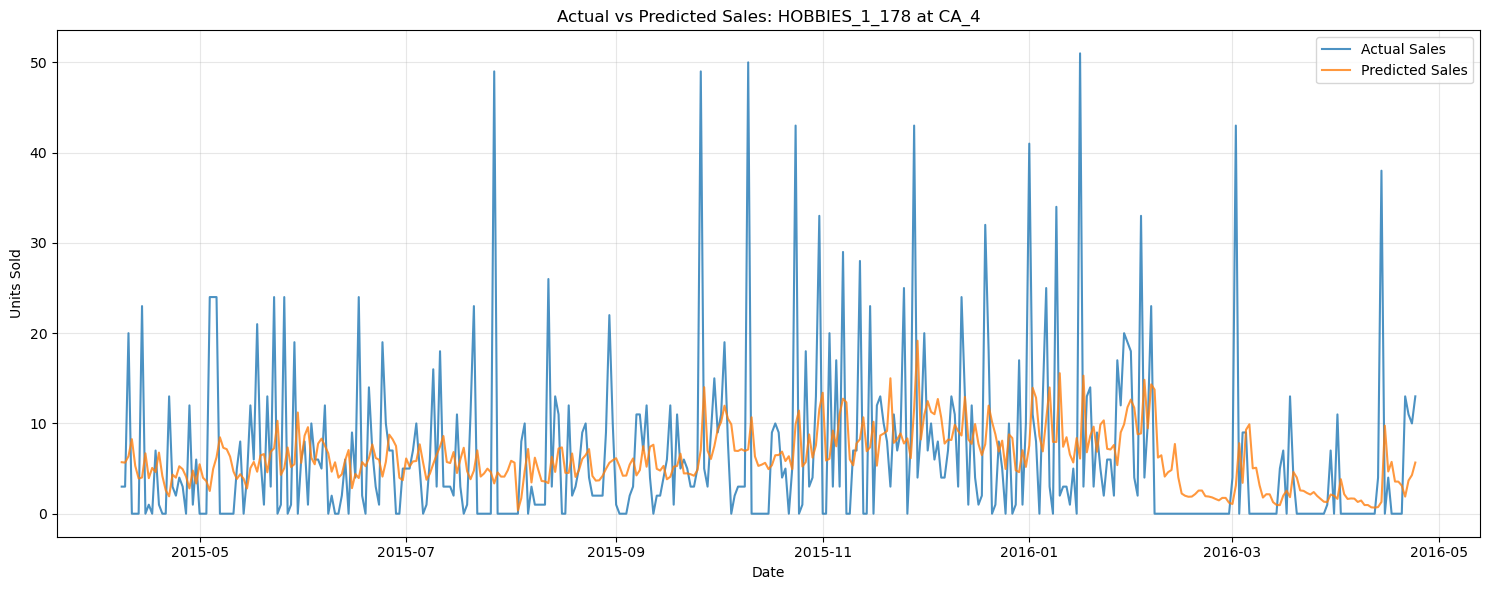

Observations: 383
Actual total sales: 2500
Predicted total sales: 2336.74
MAE: 6.216
Total absolute error: 2380.56


In [96]:
# Investigate actual vs predicted sales for HOBBIES_1_178 in CA_4

item_store = error_df[
    (error_df["store_id"] == "CA_4") &
    (error_df["item_id"] == "HOBBIES_1_178")
].copy()

item_store["date"] = pd.to_datetime(item_store["date"])
item_store = item_store.sort_values("date")

plt.figure(figsize=(15, 6))

plt.plot(
    item_store["date"],
    item_store["actual_sales"],
    label="Actual Sales",
    alpha=0.8
)

plt.plot(
    item_store["date"],
    item_store["predicted_sales"],
    label="Predicted Sales",
    alpha=0.8
)

plt.title("Actual vs Predicted Sales: HOBBIES_1_178 at CA_4")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ca4_hobbies_1_178_forecast_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Observations:", len(item_store))
print("Actual total sales:", item_store["actual_sales"].sum())
print("Predicted total sales:", round(item_store["predicted_sales"].sum(), 2))
print("MAE:", round(item_store["absolute_error"].mean(), 3))
print("Total absolute error:", round(item_store["absolute_error"].sum(), 2))

### Visualize Forecast Errors 

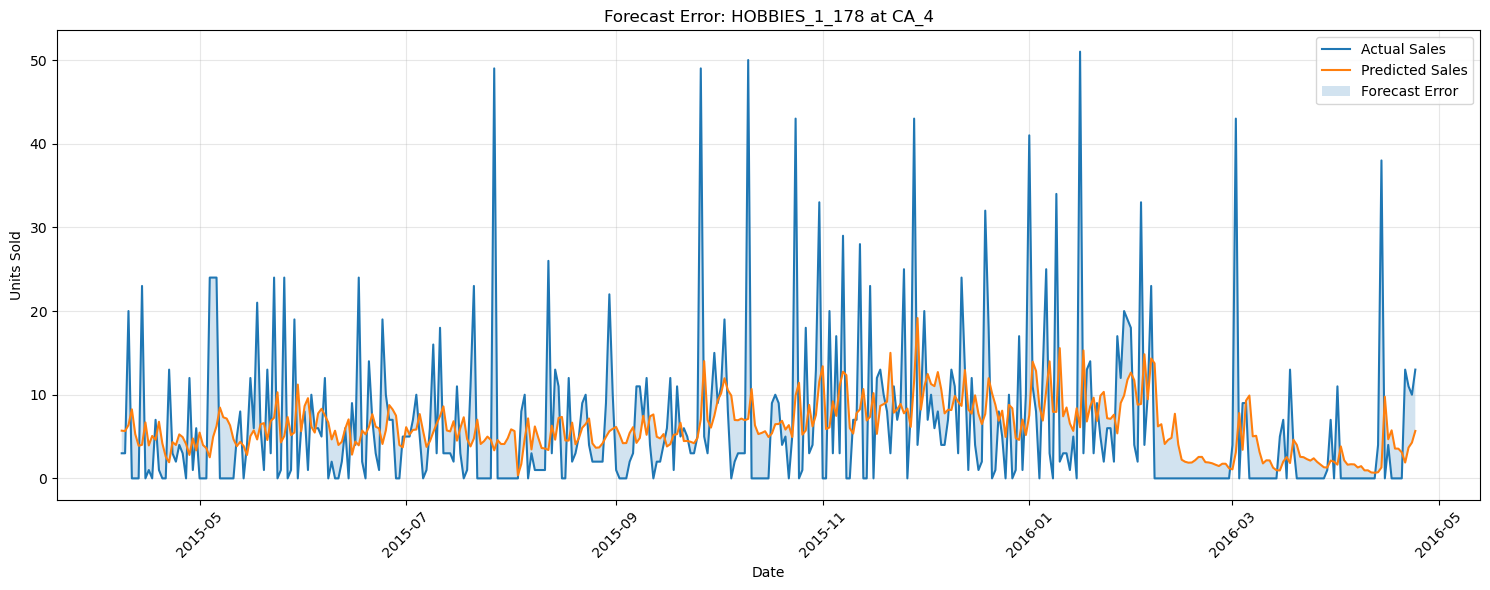

In [97]:
fig, ax = plt.subplots(figsize=(15, 6))

ax.plot(
    item_store["date"],
    item_store["actual_sales"],
    label="Actual Sales",
    linewidth=1.5
)

ax.plot(
    item_store["date"],
    item_store["predicted_sales"],
    label="Predicted Sales",
    linewidth=1.5
)

ax.fill_between(
    item_store["date"],
    item_store["actual_sales"],
    item_store["predicted_sales"],
    alpha=0.2,
    label="Forecast Error"
)

ax.set_title("Forecast Error: HOBBIES_1_178 at CA_4")
ax.set_xlabel("Date")
ax.set_ylabel("Units Sold")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ca4_hobbies_1_178_forecast_error.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### Analyze pattern across TIME PERIODS

In [98]:
# Analyze demand patterns across time periods

item_store["period"] = pd.cut(
    item_store["date"],
    bins=4,
    labels=["Period 1", "Period 2", "Period 3", "Period 4"]
)

period_analysis = (
    item_store.groupby("period", observed=False)
    .agg(
        observations=("actual_sales", "size"),
        zero_sales_days=("actual_sales", lambda x: (x == 0).sum()),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        MAE=("absolute_error", "mean"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum")
    )
    .reset_index()
)

period_analysis["zero_sales_pct"] = (
    period_analysis["zero_sales_days"]
    / period_analysis["observations"] * 100
)

period_analysis.round(2)

,period,observations,zero_sales_days,average_actual_sales,average_predicted_sales,MAE,total_actual_sales,total_predicted_sales,zero_sales_pct
0,Period 1,96,28,6.01,5.63,5.77,577,540.57,29.17
1,Period 2,96,27,6.07,5.68,5.93,583,545.70,28.12
2,Period 3,95,16,9.88,8.77,8.29,939,833.36,16.84
3,Period 4,96,60,4.18,4.34,4.90,401,417.10,62.50


### Actual vs Predicted Demand over Time 

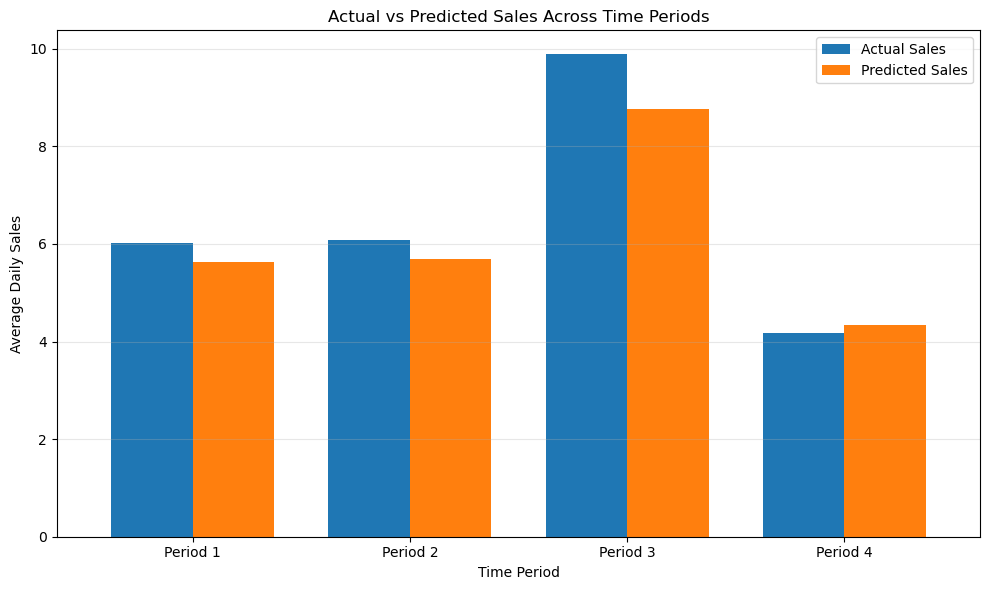

In [99]:
# Plot actual and predicted sales across the four periods

period_plot = period_analysis.set_index("period")[
    ["average_actual_sales", "average_predicted_sales"]
]

period_plot.plot(
    kind="bar",
    figsize=(10, 6),
    width=0.75
)

plt.title("Actual vs Predicted Sales Across Time Periods")
plt.xlabel("Time Period")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=0)
plt.legend(["Actual Sales", "Predicted Sales"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "hobbies_1_178_period_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Identify the largest Missed Sales Spikes 

In [100]:
# Find the days when actual sales exceeded predictions by the largest amounts

item_store["underprediction"] = (
    item_store["actual_sales"] - item_store["predicted_sales"]
)

largest_missed_spikes = (
    item_store.nlargest(10, "underprediction")[
        [
            "date",
            "item_id",
            "store_id",
            "actual_sales",
            "predicted_sales",
            "underprediction",
            "absolute_error"
        ]
    ]
    .reset_index(drop=True)
)

largest_missed_spikes.round(2)

,date,item_id,store_id,actual_sales,predicted_sales,underprediction,absolute_error
0,2015-07-27,HOBBIES_1_178,CA_4,49,3.35,45.65,45.65
1,2016-01-16,HOBBIES_1_178,CA_4,51,6.11,44.89,44.89
2,2015-10-10,HOBBIES_1_178,CA_4,50,7.11,42.89,42.89
3,2015-09-26,HOBBIES_1_178,CA_4,49,7.06,41.94,41.94
4,2016-03-02,HOBBIES_1_178,CA_4,43,3.12,39.88,39.88
5,2016-04-14,HOBBIES_1_178,CA_4,38,1.30,36.70,36.70
6,2016-01-01,HOBBIES_1_178,CA_4,41,7.54,33.46,33.46
7,2015-10-24,HOBBIES_1_178,CA_4,43,9.91,33.09,33.09
8,2015-11-28,HOBBIES_1_178,CA_4,43,11.66,31.34,31.34
9,2016-01-09,HOBBIES_1_178,CA_4,34,7.95,26.05,26.05


### Check Whether These Spikes Occur on Specific Days Of the Week 

In [101]:
# Analyze missed demand spikes by day of the week

item_store["day_of_week"] = item_store["date"].dt.day_name()

weekday_spike_analysis = (
    item_store.groupby("day_of_week")
    .agg(
        observations=("actual_sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        average_underprediction=("underprediction", "mean"),
        max_actual_sales=("actual_sales", "max"),
        average_absolute_error=("absolute_error", "mean")
    )
    .reset_index()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_spike_analysis["day_of_week"] = pd.Categorical(
    weekday_spike_analysis["day_of_week"],
    categories=weekday_order,
    ordered=True
)

weekday_spike_analysis = (
    weekday_spike_analysis
    .sort_values("day_of_week")
    .reset_index(drop=True)
)

weekday_spike_analysis.round(2)

,day_of_week,observations,average_actual_sales,average_predicted_sales,average_underprediction,max_actual_sales,average_absolute_error
0,Monday,54,4.15,5.26,-1.11,49,5.51
1,Tuesday,54,6.67,5.11,1.55,24,5.45
2,Wednesday,55,7.62,5.65,1.97,43,6.80
3,Thursday,55,5.53,5.67,-0.14,38,5.12
4,Friday,55,5.29,5.95,-0.66,41,5.16
5,Saturday,55,12.16,7.29,4.87,51,9.54
6,Sunday,55,4.24,7.74,-3.51,23,5.91


### Visualize Weekday Forecast Performance 

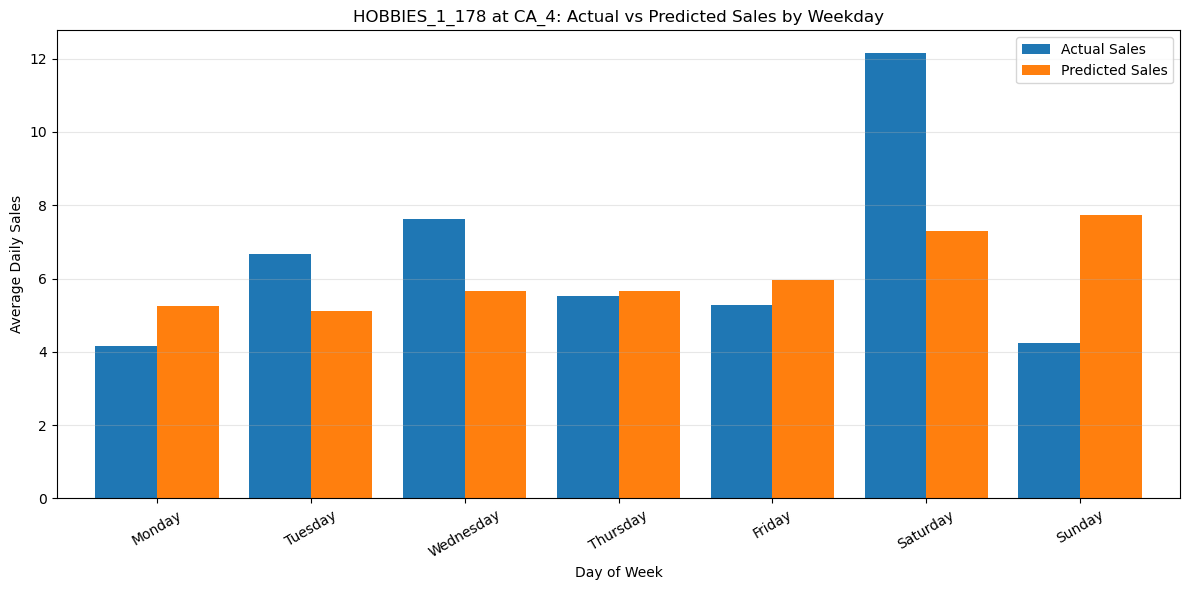

In [102]:
# Compare actual and predicted sales by weekday

weekday_plot = weekday_spike_analysis.set_index("day_of_week")[
    ["average_actual_sales", "average_predicted_sales"]
]

weekday_plot.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("HOBBIES_1_178 at CA_4: Actual vs Predicted Sales by Weekday")
plt.xlabel("Day of Week")
plt.ylabel("Average Daily Sales")
plt.xticks(rotation=30)
plt.legend(["Actual Sales", "Predicted Sales"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "ca4_hobbies_1_178_weekday_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Measure Weekday Underprediction

In [103]:
# Evaluate forecast error direction by weekday

item_store["is_underpredicted"] = (
    item_store["actual_sales"] > item_store["predicted_sales"]
)

weekday_error_summary = (
    item_store.groupby("day_of_week")
    .agg(
        observations=("actual_sales", "size"),
        MAE=("absolute_error", "mean"),
        average_underprediction=("underprediction", "mean"),
        underpredicted_days=("is_underpredicted", "sum")
    )
    .reset_index()
)

weekday_error_summary["underprediction_day_pct"] = (
    weekday_error_summary["underpredicted_days"]
    / weekday_error_summary["observations"]
    * 100
)

weekday_error_summary = (
    weekday_error_summary
    .sort_values("MAE", ascending=False)
    .reset_index(drop=True)
)

weekday_error_summary.round(2)

,day_of_week,observations,MAE,average_underprediction,underpredicted_days,underprediction_day_pct
0,Saturday,55,9.54,4.87,27,49.09
1,Wednesday,55,6.80,1.97,22,40.00
2,Sunday,55,5.91,-3.51,12,21.82
3,Monday,54,5.51,-1.11,11,20.37
4,Tuesday,54,5.45,1.55,24,44.44
5,Friday,55,5.16,-0.66,18,32.73
6,Thursday,55,5.12,-0.14,17,30.91


### Test Whether Saturday Errors are Satistically Different

In [104]:
from scipy.stats import mannwhitneyu

saturday_errors = item_store.loc[
    item_store["day_of_week"] == "Saturday",
    "absolute_error"
]

other_day_errors = item_store.loc[
    item_store["day_of_week"] != "Saturday",
    "absolute_error"
]

statistic, p_value = mannwhitneyu(
    saturday_errors,
    other_day_errors,
    alternative="greater"
)

print("Saturday observations:", len(saturday_errors))
print("Other weekday observations:", len(other_day_errors))
print("Saturday MAE:", round(saturday_errors.mean(), 3))
print("Other weekdays MAE:", round(other_day_errors.mean(), 3))
print("Mann–Whitney U statistic:", round(statistic, 3))
print("P-value:", round(p_value, 5))

if p_value < 0.05:
    print("Result: Saturday errors are significantly higher at the 5% significance level.")
else:
    print("Result: Insufficient evidence that Saturday errors are higher.")

Saturday observations: 55
Other weekday observations: 328
Saturday MAE: 9.537
Other weekdays MAE: 5.659
Mann–Whitney U statistic: 10703.0
P-value: 0.0134
Result: Saturday errors are significantly higher at the 5% significance level.


### Visualize Stastical Significance 

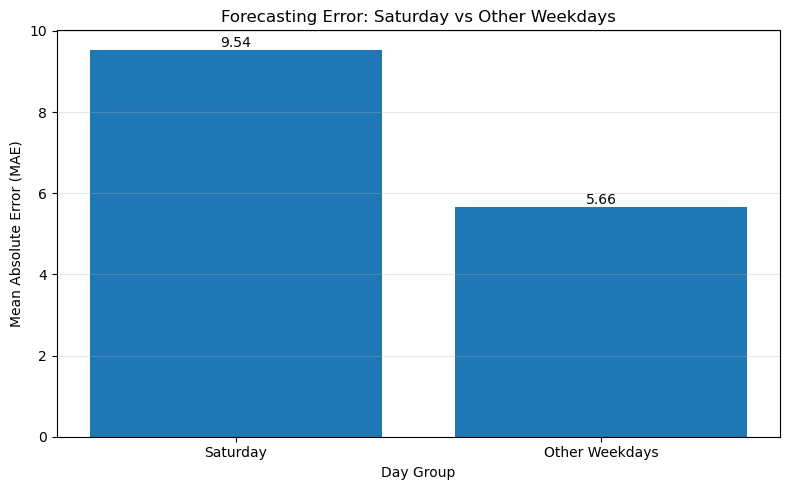

Mann–Whitney U test p-value: 0.0134


In [105]:
# Compare Saturday and other weekday forecasting errors

import matplotlib.pyplot as plt

error_comparison = pd.DataFrame({
    "Day Group": ["Saturday", "Other Weekdays"],
    "MAE": [
        saturday_errors.mean(),
        other_day_errors.mean()
    ]
})

plt.figure(figsize=(8, 5))

bars = plt.bar(
    error_comparison["Day Group"],
    error_comparison["MAE"]
)

plt.title("Forecasting Error: Saturday vs Other Weekdays")
plt.xlabel("Day Group")
plt.ylabel("Mean Absolute Error (MAE)")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f}',
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "saturday_vs_weekday_forecast_error.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

print(f"Mann–Whitney U test p-value: {p_value:.4f}")

### Check the model's saturday bias

In [106]:
# Analyze Saturday forecast bias

saturday_data = item_store[
    item_store["day_of_week"] == "Saturday"
].copy()

saturday_data["signed_error"] = (
    saturday_data["actual_sales"]
    - saturday_data["predicted_sales"]
)

print("Saturday observations:", len(saturday_data))
print("Average actual sales:", round(saturday_data["actual_sales"].mean(), 2))
print("Average predicted sales:", round(saturday_data["predicted_sales"].mean(), 2))
print("Mean signed error:", round(saturday_data["signed_error"].mean(), 2))
print(
    "Underprediction days:",
    int((saturday_data["signed_error"] > 0).sum())
)
print(
    "Overprediction days:",
    int((saturday_data["signed_error"] < 0).sum())
)
print(
    "Exact prediction days:",
    int((saturday_data["signed_error"] == 0).sum())
)

Saturday observations: 55
Average actual sales: 12.16
Average predicted sales: 7.29
Mean signed error: 4.87
Underprediction days: 27
Overprediction days: 28
Exact prediction days: 0


### Compare Typically Errors With Extreme Errors

In [107]:
# Measure how much the 5 largest Saturday errors contribute

saturday_sorted = saturday_data.sort_values(
    "absolute_error",
    ascending=False
)

top_5_saturday_errors = saturday_sorted.head(5)

total_saturday_error = saturday_data["absolute_error"].sum()
top_5_error_total = top_5_saturday_errors["absolute_error"].sum()

print("Total Saturday absolute error:", round(total_saturday_error, 2))
print("Top 5 errors combined:", round(top_5_error_total, 2))
print(
    "Share of Saturday error from top 5:",
    round(top_5_error_total / total_saturday_error * 100, 2),
    "%"
)

display(
    top_5_saturday_errors[
        [
            "date",
            "actual_sales",
            "predicted_sales",
            "absolute_error",
            "underprediction"
        ]
    ].round(2)
)

Total Saturday absolute error: 524.52
Top 5 errors combined: 194.14
Share of Saturday error from top 5: 37.01 %


,date,actual_sales,predicted_sales,absolute_error,underprediction
1008051,2016-01-16,51,6.11,44.89,44.89
1007953,2015-10-10,50,7.11,42.89,42.89
1007939,2015-09-26,49,7.06,41.94,41.94
1007967,2015-10-24,43,9.91,33.09,33.09
1008002,2015-11-28,43,11.66,31.34,31.34


### Checking whether these spikes align with calendar events

In [108]:
# Fix date data types and inspect calendar events for the largest spikes

spike_dates = top_5_saturday_errors[["date"]].copy()
spike_dates["date"] = pd.to_datetime(spike_dates["date"])

calendar_check_data = calendar.copy()
calendar_check_data["date"] = pd.to_datetime(
    calendar_check_data["date"]
)

calendar_check = spike_dates.merge(
    calendar_check_data,
    on="date",
    how="left"
)

calendar_columns = [
    col for col in [
        "date",
        "event_name_1",
        "event_type_1",
        "event_name_2",
        "event_type_2",
        "snap_CA"
    ]
    if col in calendar_check.columns
]

display(calendar_check[calendar_columns])

,date,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA
0,2016-01-16,NaN,NaN,NaN,NaN,0
1,2015-10-10,NaN,NaN,NaN,NaN,1
2,2015-09-26,NaN,NaN,NaN,NaN,0
3,2015-10-24,NaN,NaN,NaN,NaN,0
4,2015-11-28,NaN,NaN,NaN,NaN,0


### Verify SNAP and Calendar Features

In [109]:
# Inspect the original calendar feature values for the spike dates

calendar_check_data = calendar.copy()
calendar_check_data["date"] = pd.to_datetime(
    calendar_check_data["date"]
)

feature_columns = [
    col for col in [
        "date",
        "event_name_1",
        "event_type_1",
        "event_name_2",
        "event_type_2",
        "snap_CA",
        "snap_TX",
        "snap_WI"
    ]
    if col in calendar_check_data.columns
]

display(
    calendar_check_data[
        calendar_check_data["date"].isin(
            pd.to_datetime(top_5_saturday_errors["date"])
        )
    ][feature_columns].sort_values("date")
)

print("\nMissing values in selected calendar features:")
print(
    calendar_check_data[feature_columns]
    .isna()
    .sum()
)

,date,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
1701,2015-09-26,NaN,NaN,NaN,NaN,0,0,0
1715,2015-10-10,NaN,NaN,NaN,NaN,1,0,0
1729,2015-10-24,NaN,NaN,NaN,NaN,0,0,0
1764,2015-11-28,NaN,NaN,NaN,NaN,0,0,0
1813,2016-01-16,NaN,NaN,NaN,NaN,0,0,0



Missing values in selected calendar features:
date               0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64


###  Verify California SNAP and event indicators for the five largest spikes

In [110]:


spike_dates = pd.to_datetime(
    top_5_saturday_errors["date"]
)

calendar_features = calendar.copy()
calendar_features["date"] = pd.to_datetime(
    calendar_features["date"]
)

calendar_spike_check = (
    calendar_features[
        calendar_features["date"].isin(spike_dates)
    ][
        [
            "date",
            "event_name_1",
            "event_name_2",
            "snap_CA",
            "snap_TX",
            "snap_WI"
        ]
    ]
    .sort_values("date")
    .reset_index(drop=True)
)

print(calendar_spike_check.to_string(index=False))

      date event_name_1 event_name_2  snap_CA  snap_TX  snap_WI
2015-09-26          NaN          NaN        0        0        0
2015-10-10          NaN          NaN        1        0        0
2015-10-24          NaN          NaN        0        0        0
2015-11-28          NaN          NaN        0        0        0
2016-01-16          NaN          NaN        0        0        0


### Check whether spikes repeat on Saturdays

In [111]:
# Analyze Saturday demand spikes for this item-store combination

item_store["date"] = pd.to_datetime(item_store["date"])

saturday_analysis = item_store[
    item_store["date"].dt.dayofweek == 5
].copy()

saturday_analysis["year_month"] = (
    saturday_analysis["date"].dt.to_period("M").astype(str)
)

monthly_saturday = (
    saturday_analysis.groupby("year_month")
    .agg(
        saturday_observations=("sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        maximum_actual_sales=("actual_sales", "max"),
        total_actual_sales=("actual_sales", "sum"),
        total_absolute_error=("absolute_error", "sum")
    )
    .reset_index()
)

monthly_saturday["average_absolute_error"] = (
    monthly_saturday["total_absolute_error"]
    / monthly_saturday["saturday_observations"]
)

print(monthly_saturday.to_string(index=False))

year_month  saturday_observations  average_actual_sales  average_predicted_sales  maximum_actual_sales  total_actual_sales  total_absolute_error  average_absolute_error
   2015-04                      3              3.666667                 6.044848                     7                  11             11.893318                3.964439
   2015-05                      5              7.200000                 6.929635                    24                  36             46.049884                9.209977
   2015-06                      4              8.000000                 7.158141                    14                  32             12.476926                3.119232
   2015-07                      4              7.000000                 6.394520                    18                  28             27.022500                6.755625
   2015-08                      5              6.000000                 6.061874                    11                  30             21.832404           

### Visualize the monthly pattern

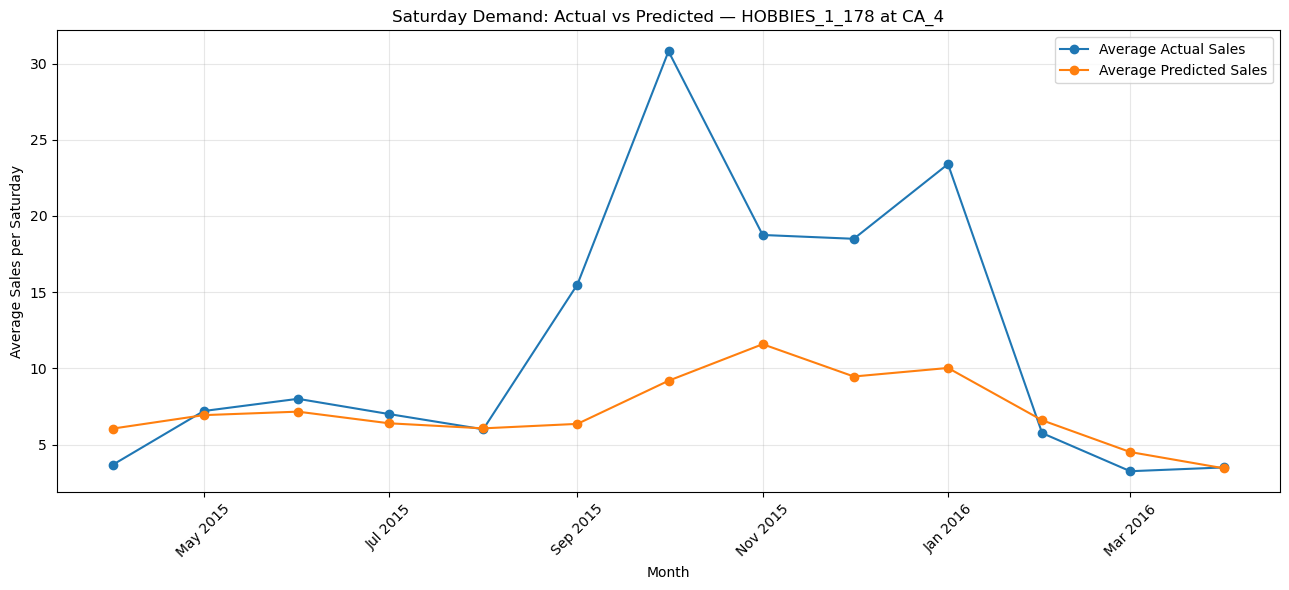

In [112]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

monthly_plot = monthly_saturday.copy()
monthly_plot["month"] = pd.to_datetime(
    monthly_plot["year_month"] + "-01"
)

fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(
    monthly_plot["month"],
    monthly_plot["average_actual_sales"],
    marker="o",
    label="Average Actual Sales"
)

ax.plot(
    monthly_plot["month"],
    monthly_plot["average_predicted_sales"],
    marker="o",
    label="Average Predicted Sales"
)

ax.set_title(
    "Saturday Demand: Actual vs Predicted — HOBBIES_1_178 at CA_4"
)
ax.set_xlabel("Month")
ax.set_ylabel("Average Sales per Saturday")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(True, alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "ca4_hobbies_1_178_monthly_saturday_analysis.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### check whether the surge was item-specific

In [113]:
# Check Saturday demand across all items in CA_4
# during the demand-surge months

surge_months = ["2015-10", "2016-01"]

store_saturday = error_df[
    (error_df["store_id"] == "CA_4") &
    (error_df["date"].dt.dayofweek == 5) &
    (error_df["date"].dt.to_period("M").astype(str).isin(surge_months))
].copy()

store_saturday["year_month"] = (
    store_saturday["date"].dt.to_period("M").astype(str)
)

store_surge_summary = (
    store_saturday.groupby("year_month")
    .agg(
        item_store_observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

store_surge_summary["WAPE_percent"] = (
    (
        store_saturday.groupby("year_month")["absolute_error"].sum().values
        / store_surge_summary["total_actual_sales"]
    ) * 100
)

print(store_surge_summary.to_string(index=False))

year_month  item_store_observations  total_actual_sales  total_predicted_sales      MAE  WAPE_percent
   2015-10                      580                 635             528.667716 0.920296     84.058498
   2016-01                      580                 579             507.021392 0.865213     86.670778


### Create an SVG chart

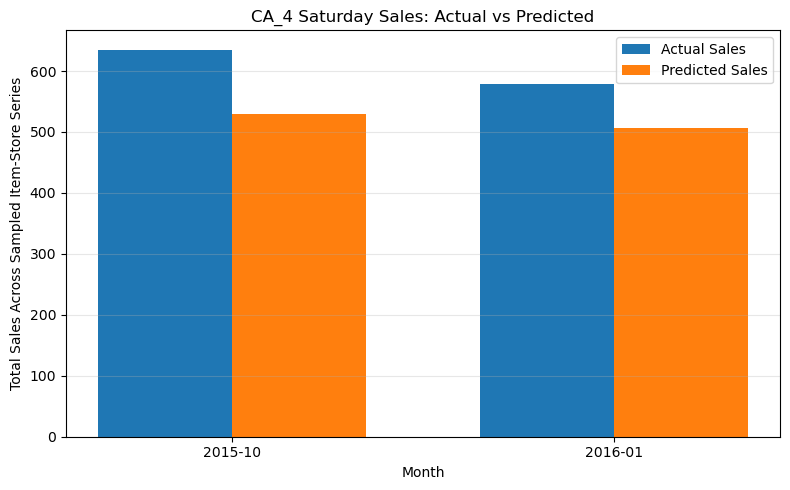

In [114]:
import matplotlib.pyplot as plt

months = store_surge_summary["year_month"]

fig, ax = plt.subplots(figsize=(8, 5))

x = range(len(months))
width = 0.35

ax.bar(
    [i - width / 2 for i in x],
    store_surge_summary["total_actual_sales"],
    width=width,
    label="Actual Sales"
)

ax.bar(
    [i + width / 2 for i in x],
    store_surge_summary["total_predicted_sales"],
    width=width,
    label="Predicted Sales"
)

ax.set_xticks(list(x))
ax.set_xticklabels(months)
ax.set_title("CA_4 Saturday Sales: Actual vs Predicted")
ax.set_xlabel("Month")
ax.set_ylabel("Total Sales Across Sampled Item-Store Series")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "ca4_store_saturday_surge_comparison.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### Analyze Forecast Errors by Demand Level in CA_4

In [115]:
# Analyze forecast errors by demand level in CA_4

ca4_errors = error_df[error_df["store_id"] == "CA_4"].copy()

ca4_errors["demand_level"] = pd.cut(
    ca4_errors["actual_sales"],
    bins=[-0.001, 0, 1, 5, 10, float("inf")],
    labels=[
        "Zero sales",
        "1 unit",
        "2–5 units",
        "6–10 units",
        "Above 10 units"
    ]
)

ca4_demand_analysis = (
    ca4_errors.groupby("demand_level", observed=False)
    .agg(
        observations=("actual_sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        MAE=("absolute_error", "mean"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum")
    )
    .reset_index()
)

ca4_demand_analysis["WAPE_percent"] = (
    ca4_errors.groupby("demand_level", observed=False)["absolute_error"].sum().values
    / ca4_demand_analysis["total_actual_sales"].replace(0, float("nan"))
    * 100
)

print(ca4_demand_analysis.to_string(index=False))

  demand_level  observations  average_actual_sales  average_predicted_sales       MAE  total_actual_sales  total_predicted_sales  WAPE_percent
    Zero sales         30102              0.000000                 0.437453  0.437453                   0           13168.211712           NaN
        1 unit          7531              1.000000                 0.829541  0.584170                7531            6247.272635     58.416993
     2–5 units          5770              2.750433                 1.776494  1.560296               15870           10250.370833     56.729090
    6–10 units           750              7.268000                 4.041247  3.459821                5451            3030.935143     47.603474
Above 10 units           275             17.741818                 5.533316 12.229944                4879            1521.661841     68.932868


### Measure Underprediction by DEMAND LEVEL

In [116]:
# Measure underprediction frequency by demand level in CA_4

ca4_errors["error_direction"] = np.select(
    [
        ca4_errors["actual_sales"] > ca4_errors["predicted_sales"],
        ca4_errors["actual_sales"] < ca4_errors["predicted_sales"]
    ],
    [
        "Underprediction",
        "Overprediction"
    ],
    default="Exact prediction"
)

direction_analysis = (
    ca4_errors.groupby(
        ["demand_level", "error_direction"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

direction_analysis["total_observations"] = direction_analysis.sum(axis=1)

direction_analysis["underprediction_pct"] = (
    direction_analysis.get("Underprediction", 0)
    / direction_analysis["total_observations"]
    * 100
)

print(direction_analysis.to_string())

error_direction  Exact prediction  Overprediction  Underprediction  total_observations  underprediction_pct
demand_level                                                                                               
Zero sales                   1313           28789                0               30102             0.000000
1 unit                          0            1877             5654                7531            75.076351
2–5 units                       0            1080             4690                5770            81.282496
6–10 units                      0              69              681                 750            90.800000
Above 10 units                  0               1              274                 275            99.636364


### Create an SVG chart

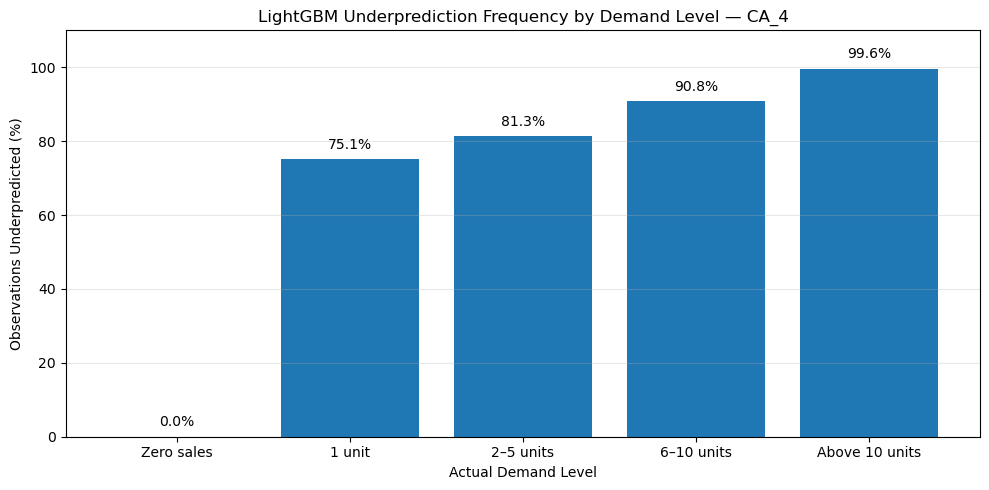

In [117]:
import matplotlib.pyplot as plt

plot_data = direction_analysis.reset_index()

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    plot_data["demand_level"].astype(str),
    plot_data["underprediction_pct"]
)

ax.set_title("LightGBM Underprediction Frequency by Demand Level — CA_4")
ax.set_xlabel("Actual Demand Level")
ax.set_ylabel("Observations Underpredicted (%)")
ax.set_ylim(0, 110)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_data["underprediction_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "ca4_underprediction_by_demand_level.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### Identify the items contributing most to underprediction

In [118]:
# Find the 10 items with the largest total underprediction in CA_4

ca4_errors["underprediction_amount"] = (
    ca4_errors["actual_sales"] - ca4_errors["predicted_sales"]
).clip(lower=0)

top_underpredicted_items = (
    ca4_errors.groupby("item_id")
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        total_underprediction=("underprediction_amount", "sum"),
        MAE=("absolute_error", "mean")
    )
    .sort_values("total_underprediction", ascending=False)
    .head(10)
    .reset_index()
)

print(top_underpredicted_items.to_string(index=False))

      item_id  observations  total_actual_sales  total_predicted_sales  total_underprediction      MAE
HOBBIES_1_178           383                2500            2336.740800            1271.909832 6.215563
HOBBIES_1_295           383                2397            2302.209197             921.502169 4.564526
HOBBIES_1_008           383                1936            1869.567987             812.742637 4.070635
HOBBIES_1_288           383                1717            1669.944116             741.159800 3.747425
  FOODS_3_234           383                1256            1242.203570             678.431516 3.506701
  FOODS_2_019           383                1343            1317.662761             371.229600 1.872381
  FOODS_2_241           383                1458            1435.643528             365.221458 1.848790
  FOODS_3_227           383                 799             798.395320             282.126595 1.471667
  FOODS_2_036           383                 648             645.824555   

### Create an SVG chart of the top 10 items

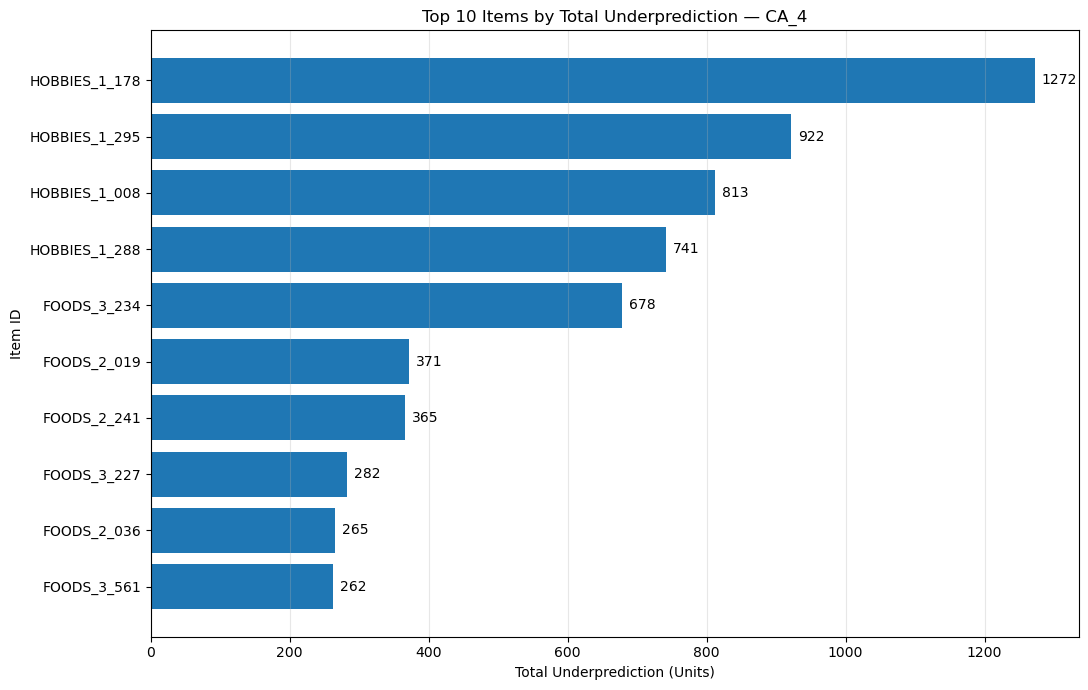

In [119]:
import matplotlib.pyplot as plt

plot_data = top_underpredicted_items.sort_values(
    "total_underprediction",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    plot_data["item_id"],
    plot_data["total_underprediction"]
)

ax.set_title("Top 10 Items by Total Underprediction — CA_4")
ax.set_xlabel("Total Underprediction (Units)")
ax.set_ylabel("Item ID")
ax.grid(axis="x", alpha=0.3)

for bar, value in zip(bars, plot_data["total_underprediction"]):
    ax.text(
        bar.get_width() + 10,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.0f}",
        va="center"
    )

plt.tight_layout()

plt.savefig(
    "ca4_top10_underpredicted_items.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### Check demand spikes across the top 10 items

In [120]:
# Analyze high-demand observations for the top 10 underpredicted items

top_item_ids = top_underpredicted_items["item_id"].tolist()

top_items_analysis = ca4_errors[
    ca4_errors["item_id"].isin(top_item_ids)
].copy()

item_spike_analysis = (
    top_items_analysis.groupby("item_id")
    .agg(
        observations=("actual_sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        maximum_actual_sales=("actual_sales", "max"),
        days_above_10_units=(
            "actual_sales",
            lambda x: (x > 10).sum()
        ),
        days_above_20_units=(
            "actual_sales",
            lambda x: (x > 20).sum()
        ),
        total_underprediction=("underprediction_amount", "sum"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
    .sort_values("total_underprediction", ascending=False)
)

print(item_spike_analysis.to_string(index=False))

      item_id  observations  average_actual_sales  maximum_actual_sales  days_above_10_units  days_above_20_units  total_underprediction      MAE
HOBBIES_1_178           383              6.527415                    51                   83                   31            1271.909832 6.215563
HOBBIES_1_295           383              6.258486                    35                   63                   12             921.502169 4.564526
HOBBIES_1_008           383              5.054830                    30                   58                    9             812.742637 4.070635
HOBBIES_1_288           383              4.483029                    36                   34                   10             741.159800 3.747425
  FOODS_3_234           383              3.279373                    52                   26                    3             678.431516 3.506701
  FOODS_2_019           383              3.506527                    10                    0                    0           

### Your results support a strong relationship between high-demand spikes and total underprediction for several items in CA_4.

##### HOBBIES_1_178: 83 days above 10 units, 31 days above 20 units, maximum sales of 51.
##### HOBBIES_1_295: 63 days above 10 units, maximum sales of 35.
##### HOBBIES_1_008: 58 days above 10 units, maximum sales of 30.
##### FOODS_3_234: Maximum sales of 52 despite an average demand of only 3.28 units.

### Compare demand spikes against predictions

###### Let's quantify how much LightGBM underpredicts on high-demand days for these 10 items.

In [121]:
# Compare actual and predicted sales on high-demand days

spike_analysis = top_items_analysis.copy()

spike_analysis["demand_group"] = np.where(
    spike_analysis["actual_sales"] > 10,
    "High demand (>10)",
    "Normal demand (<=10)"
)

spike_summary = (
    spike_analysis.groupby(["item_id", "demand_group"])
    .agg(
        observations=("actual_sales", "size"),
        average_actual=("actual_sales", "mean"),
        average_predicted=("predicted_sales", "mean"),
        average_absolute_error=("absolute_error", "mean"),
        total_underprediction=("underprediction_amount", "sum")
    )
    .reset_index()
)

print(spike_summary.to_string(index=False))

      item_id         demand_group  observations  average_actual  average_predicted  average_absolute_error  total_underprediction
  FOODS_2_019 Normal demand (<=10)           383        3.506527           3.440373                1.872381             371.229600
  FOODS_2_036 Normal demand (<=10)           383        1.691906           1.686226                1.380653             265.482855
  FOODS_2_241    High demand (>10)             8       13.000000           4.896853                8.103147              64.825173
  FOODS_2_241 Normal demand (<=10)           375        3.610667           3.723917                1.715363             300.396285
  FOODS_3_227    High demand (>10)             1       11.000000           1.850075                9.149925               9.149925
  FOODS_3_227 Normal demand (<=10)           382        2.062827           2.085197                1.451567             272.976670
  FOODS_3_234    High demand (>10)            26       17.153846           3.084489

### Visualize high-demand forecasting errors

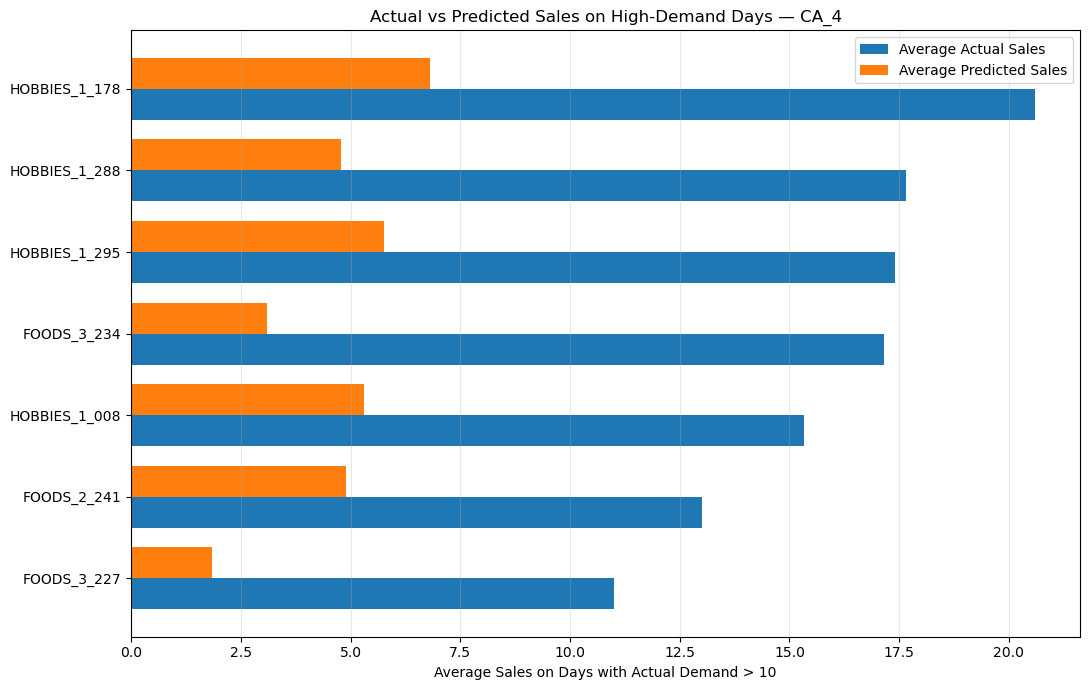

In [122]:
# Compare actual vs predicted sales on high-demand days

high_demand_summary = (
    spike_summary[
        spike_summary["demand_group"] == "High demand (>10)"
    ]
    .sort_values("average_actual", ascending=True)
    .copy()
)

fig, ax = plt.subplots(figsize=(11, 7))

y = np.arange(len(high_demand_summary))
height = 0.38

ax.barh(
    y - height / 2,
    high_demand_summary["average_actual"],
    height,
    label="Average Actual Sales"
)

ax.barh(
    y + height / 2,
    high_demand_summary["average_predicted"],
    height,
    label="Average Predicted Sales"
)

ax.set_yticks(y)
ax.set_yticklabels(high_demand_summary["item_id"])
ax.set_title("Actual vs Predicted Sales on High-Demand Days — CA_4")
ax.set_xlabel("Average Sales on Days with Actual Demand > 10")
ax.legend()
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "ca4_high_demand_actual_vs_predicted.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

### Check whether Lag Features Capture Demand Spikes

In [123]:
# Inspect lag features around high-demand days for HOBBIES_1_178 at CA_4

spike_item = error_df[
    (error_df["item_id"] == "HOBBIES_1_178") &
    (error_df["store_id"] == "CA_4")
].copy()

spike_item["date"] = pd.to_datetime(spike_item["date"])

# Join the original feature data to inspect lag values
lag_columns = [
    "date", "item_id", "store_id",
    "lag_1", "lag_7", "lag_28",
    "rolling_mean_7", "rolling_mean_28"
]

feature_data = test_df[lag_columns].copy()
feature_data["date"] = pd.to_datetime(feature_data["date"])

spike_item = spike_item.merge(
    feature_data,
    on=["date", "item_id", "store_id"],
    how="left"
)

spike_days = spike_item[spike_item["actual_sales"] > 10].copy()

lag_summary = spike_days[
    [
        "date", "actual_sales", "predicted_sales",
        "lag_1", "lag_7", "lag_28",
        "rolling_mean_7", "rolling_mean_28"
    ]
].sort_values("actual_sales", ascending=False)

print(lag_summary.head(15).to_string(index=False))

      date  actual_sales  predicted_sales  lag_1  lag_7  lag_28  rolling_mean_7  rolling_mean_28
2016-01-16            51         6.108058    0.0   34.0    32.0        6.857143         9.000000
2015-10-10            50         7.114325    3.0   19.0     0.0        5.428571         7.285714
2015-09-26            49         7.059723    5.0   11.0     9.0        5.428571         5.607143
2015-07-27            49         3.354241    0.0   11.0     0.0        4.857143         5.035714
2015-10-24            43         9.908949    5.0    9.0    49.0        6.000000         8.250000
2016-03-02            43         3.115165    4.0    0.0    33.0        0.571429         2.642857
2015-11-28            43        11.664163    8.0    3.0    33.0        9.000000         9.857143
2016-01-01            41         7.541298   10.0    0.0     6.0        5.571429         7.714286
2016-04-14            38         1.303799    4.0    0.0     0.0        0.571429         1.428571
2016-01-09            34      

### Quantify how often lag features provide warning signals

In [124]:
# Categorize high-demand days by the previous week's sales

spike_days["lag7_signal"] = np.where(
    spike_days["lag_7"] >= 10,
    "High lag_7 (>=10)",
    "Low lag_7 (<10)"
)

lag7_analysis = (
    spike_days.groupby("lag7_signal")
    .agg(
        observations=("actual_sales", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        average_lag_7=("lag_7", "mean"),
        average_absolute_error=("absolute_error", "mean")
    )
    .reset_index()
)

print(lag7_analysis.to_string(index=False))

      lag7_signal  observations  average_actual_sales  average_predicted_sales  average_lag_7  average_absolute_error
High lag_7 (>=10)            30             24.633333                 7.510471      18.833333               17.319411
  Low lag_7 (<10)            53             18.301887                 6.406627       3.018868               11.895260


### Check how the model uses lag features

        feature  importance
 rolling_mean_7        3005
          lag_1        2913
          lag_7        2123
         lag_28        2083
rolling_mean_28        1711
          month        1214
    day_of_week        1110
        snap_WI         278
        snap_TX         245
        snap_CA         229
       is_event          89


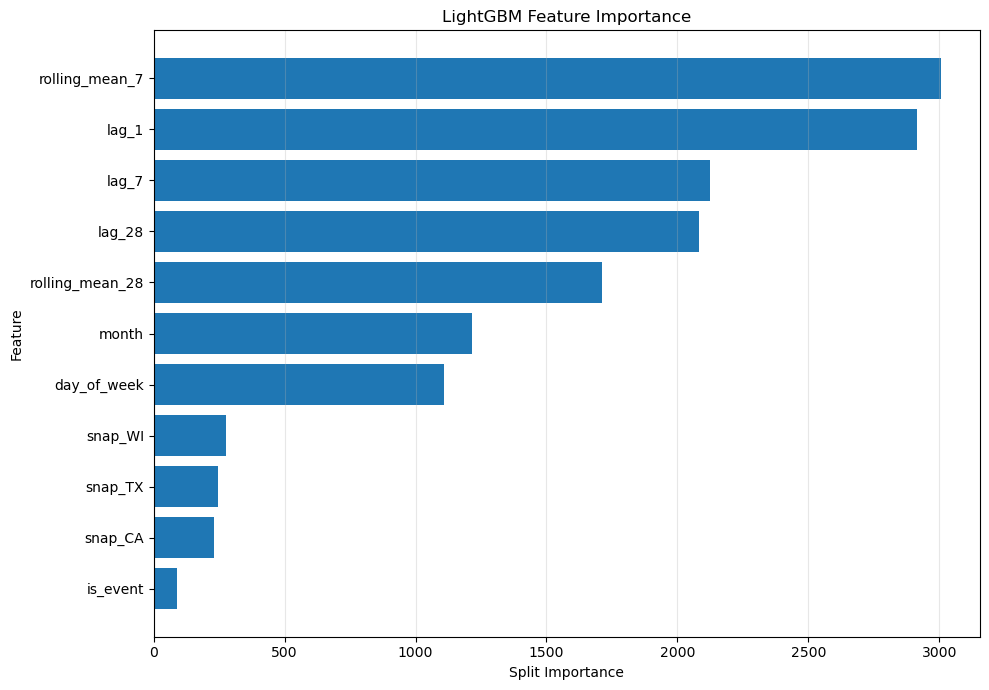

In [135]:
# Inspect LightGBM feature importance

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance", ascending=False
)

print(feature_importance.to_string(index=False))

# Create an SVG chart
import matplotlib.pyplot as plt

plot_data = feature_importance.sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(plot_data["feature"], plot_data["importance"])

ax.set_title("LightGBM Feature Importance")
ax.set_xlabel("Split Importance")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "lightgbm_feature_importance.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

In [130]:
# Find variables in memory that may contain the trained LightGBM model

for name, obj in globals().copy().items():
    if "lightgbm" in str(type(obj)).lower() or "booster" in str(type(obj)).lower():
        print(name, type(obj))

lgb_model <class 'lightgbm.sklearn.LGBMRegressor'>
lgb_price <class 'lightgbm.sklearn.LGBMRegressor'>


        feature  importance
 rolling_mean_7        3005
          lag_1        2913
          lag_7        2123
         lag_28        2083
rolling_mean_28        1711
          month        1214
    day_of_week        1110
        snap_WI         278
        snap_TX         245
        snap_CA         229
       is_event          89


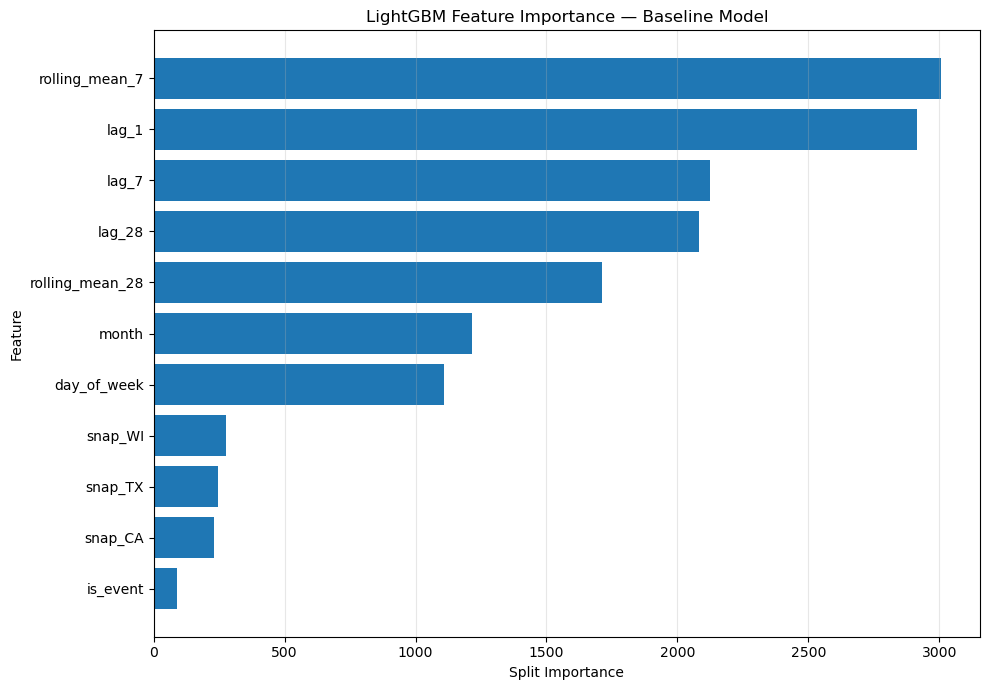

In [131]:
# Feature importance for the baseline LightGBM model

feature_importance = pd.DataFrame({
    "feature": lgb_model.feature_name_,
    "importance": lgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance", ascending=False
)

print(feature_importance.to_string(index=False))

# Create SVG chart
import matplotlib.pyplot as plt

plot_data = feature_importance.sort_values("importance")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data["feature"],
    plot_data["importance"]
)

ax.set_title("LightGBM Feature Importance — Baseline Model")
ax.set_xlabel("Split Importance")
ax.set_ylabel("Feature")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "lightgbm_feature_importance.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

In [132]:
# Analyze forecast errors against recent sales patterns

error_feature_analysis = error_df.copy()

# Add recent-sales features from the test data
error_feature_analysis = error_feature_analysis.merge(
    X_test[["rolling_mean_7", "rolling_mean_28"]],
    left_index=True,
    right_index=True,
    how="left"
)

error_feature_analysis["error_size"] = pd.cut(
    error_feature_analysis["absolute_error"],
    bins=[-0.001, 1, 5, 10, float("inf")],
    labels=["Low (≤1)", "Moderate (1–5)", "High (5–10)", "Very high (>10)"]
)

error_vs_recent_sales = (
    error_feature_analysis
    .groupby("error_size", observed=True)
    .agg(
        observations=("absolute_error", "size"),
        average_actual=("actual_sales", "mean"),
        average_predicted=("predicted_sales", "mean"),
        average_rolling_7=("rolling_mean_7", "mean"),
        average_rolling_28=("rolling_mean_28", "mean"),
        average_absolute_error=("absolute_error", "mean")
    )
    .reset_index()
)

print(error_vs_recent_sales.to_string(index=False))

     error_size  observations  average_actual  average_predicted  average_rolling_7  average_rolling_28  average_absolute_error
       Low (≤1)        290185        0.485570           0.625635           1.146932            1.128812                0.362381
 Moderate (1–5)         85206        2.500129           2.345849           0.915207            0.901959                1.971460
    High (5–10)          5925        9.150717           7.162227           0.285714            0.285714                6.643556
Very high (>10)          1684       21.660926          12.384657                NaN                 NaN               15.433887


### Fix and create the SVG chart

error_df: (383000, 10)
test_df: (383000, 36)

Error analysis:
     error_size  observations  average_actual  average_predicted  average_rolling_7  average_rolling_28  average_absolute_error
       Low (≤1)        290185        0.485570           0.625635           0.603662            0.615130                0.362381
 Moderate (1–5)         85206        2.500129           2.345849           2.397350            2.371062                1.971460
    High (5–10)          5925        9.150717           7.162227           7.410247            7.096606                6.643556
Very high (>10)          1684       21.660926          12.384657          12.288259           11.609200               15.433887


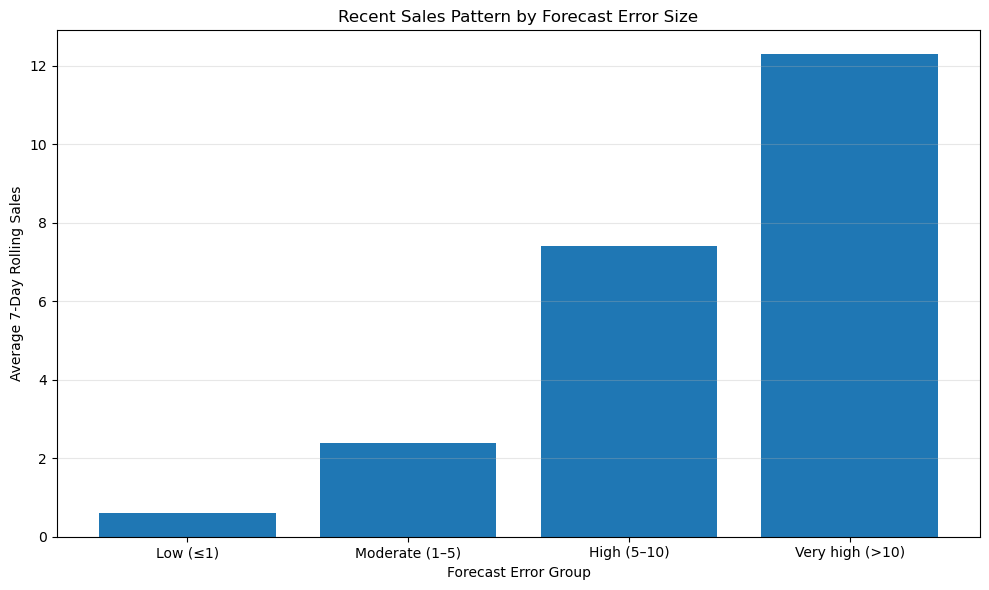

<Figure size 640x480 with 0 Axes>

In [138]:
import matplotlib.pyplot as plt
import pandas as pd

# Use the full test dataset, which matches error_df
print("error_df:", error_df.shape)
print("test_df:", test_df.shape)

# Align rows using their original index
error_feature_analysis = error_df.copy()

rolling_features = test_df[
    ["rolling_mean_7", "rolling_mean_28"]
].reindex(error_feature_analysis.index)

error_feature_analysis[
    ["rolling_mean_7", "rolling_mean_28"]
] = rolling_features

# Group observations by absolute forecast error
error_feature_analysis["error_size"] = pd.cut(
    error_feature_analysis["absolute_error"],
    bins=[-0.001, 1, 5, 10, float("inf")],
    labels=["Low (≤1)", "Moderate (1–5)", "High (5–10)", "Very high (>10)"]
)

error_vs_recent_sales = (
    error_feature_analysis
    .groupby("error_size", observed=True)
    .agg(
        observations=("absolute_error", "size"),
        average_actual=("actual_sales", "mean"),
        average_predicted=("predicted_sales", "mean"),
        average_rolling_7=("rolling_mean_7", "mean"),
        average_rolling_28=("rolling_mean_28", "mean"),
        average_absolute_error=("absolute_error", "mean")
    )
    .reset_index()
)

print("\nError analysis:")
print(error_vs_recent_sales.to_string(index=False))

# Create SVG chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    error_vs_recent_sales["error_size"].astype(str),
    error_vs_recent_sales["average_rolling_7"]
)

ax.set_title("Recent Sales Pattern by Forecast Error Size")
ax.set_xlabel("Forecast Error Group")
ax.set_ylabel("Average 7-Day Rolling Sales")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "error_size_vs_recent_sales.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()
plt.savefig(
    "error_size_vs_recent_sales.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

In [ ]:
### Identify which error are most predictable

recent_demand_level  observations  average_actual_sales  average_predicted_sales  average_absolute_error  median_absolute_error
    Very low (≤0.5)        195846              0.261573                 0.251731                0.373577               0.251469
        Low (0.5–2)        133255              1.022806                 1.032672                0.944273               0.722227
     Moderate (2–5)         38507              3.012647                 3.006429                1.928990               1.535474
          High (>5)         15392              9.166840                 9.228455                4.237213               3.141340


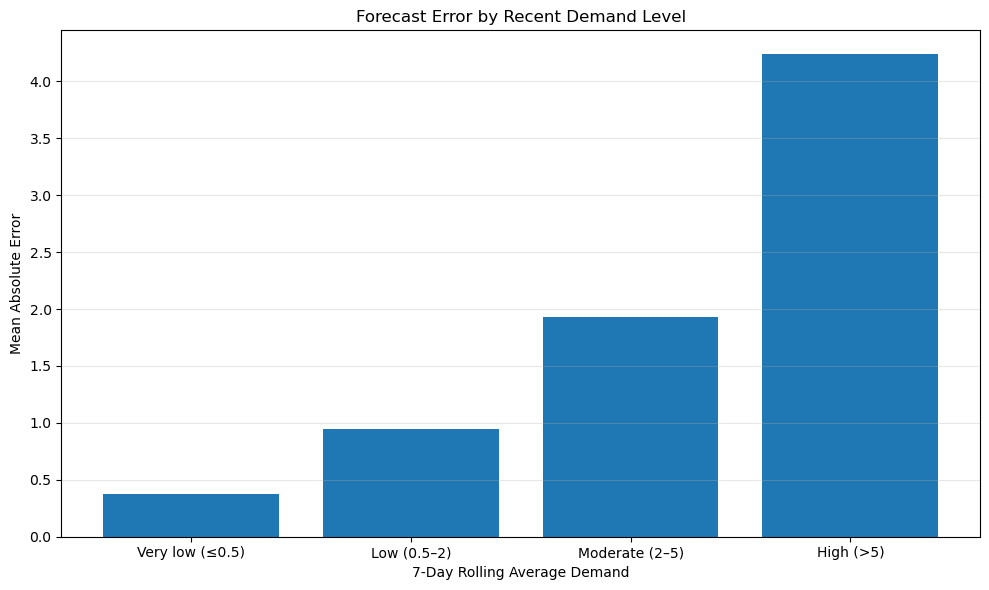

In [140]:
# Day 6: Error analysis by recent demand level

error_feature_analysis["recent_demand_level"] = pd.cut(
    error_feature_analysis["rolling_mean_7"],
    bins=[-0.001, 0.5, 2, 5, float("inf")],
    labels=[
        "Very low (≤0.5)",
        "Low (0.5–2)",
        "Moderate (2–5)",
        "High (>5)"
    ]
)

recent_demand_error = (
    error_feature_analysis
    .groupby("recent_demand_level", observed=True)
    .agg(
        observations=("absolute_error", "size"),
        average_actual_sales=("actual_sales", "mean"),
        average_predicted_sales=("predicted_sales", "mean"),
        average_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median")
    )
    .reset_index()
)

print(recent_demand_error.to_string(index=False))

# Save the results as an SVG chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    recent_demand_error["recent_demand_level"].astype(str),
    recent_demand_error["average_absolute_error"]
)

ax.set_title("Forecast Error by Recent Demand Level")
ax.set_xlabel("7-Day Rolling Average Demand")
ax.set_ylabel("Mean Absolute Error")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "forecast_error_by_recent_demand.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

### Identify the Worst-Predicted Items

        item_id  observations  total_actual_sales  total_predicted_sales  total_underprediction      MAE
  HOBBIES_1_178          1149                4723            4500.699880            2294.951426 3.801221
    FOODS_3_723           383                8600            8378.181922            1719.852205 8.401792
  HOBBIES_1_371           766                4465            4300.173418            1713.061248 4.257566
    FOODS_3_288           383               10061            9731.517461            1676.706831 7.895382
HOUSEHOLD_1_465           383                5733            5453.523093            1635.662781 7.811615
    FOODS_3_389           766                9867            9625.661464            1594.603409 3.848392
    FOODS_1_218           383                5389            5184.390784            1279.825225 6.148933
    FOODS_3_252           383                6940            6672.083007            1254.565967 5.851736
HOUSEHOLD_1_521           383                5741      

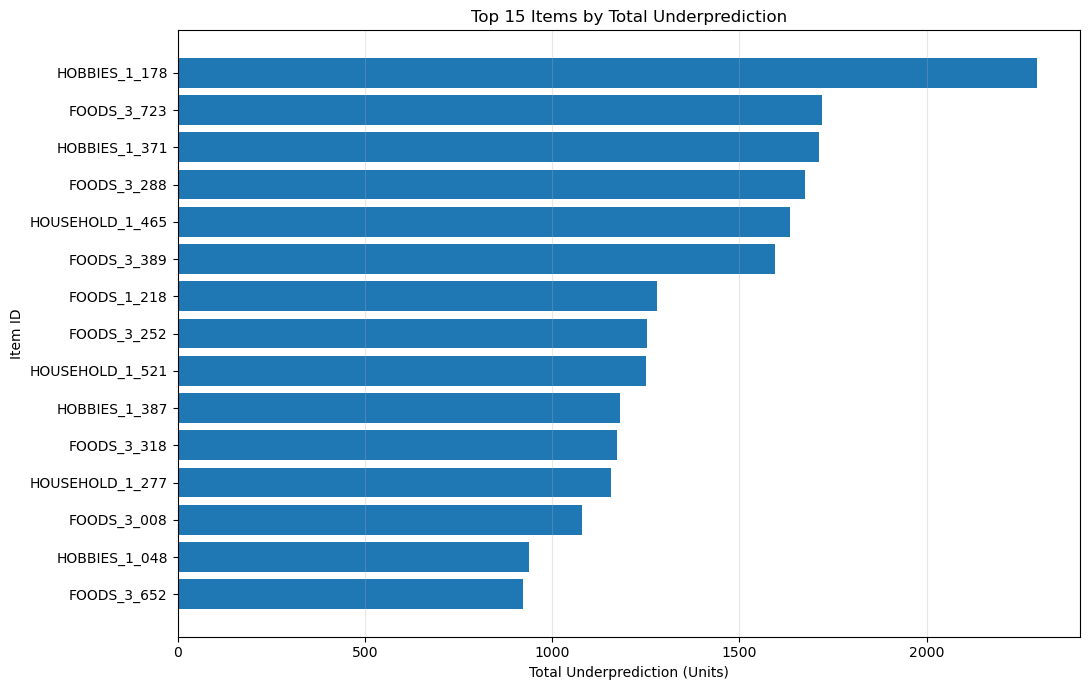

In [141]:
# Day 6: Identify items with the largest underprediction

error_feature_analysis["underprediction"] = (
    error_feature_analysis["actual_sales"]
    - error_feature_analysis["predicted_sales"]
).clip(lower=0)

top_underpredicted_items = (
    error_feature_analysis
    .groupby("item_id")
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        total_underprediction=("underprediction", "sum"),
        MAE=("absolute_error", "mean")
    )
    .sort_values("total_underprediction", ascending=False)
    .head(15)
    .reset_index()
)

print(top_underpredicted_items.to_string(index=False))

# Create SVG chart
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = top_underpredicted_items.sort_values(
    "total_underprediction"
)

ax.barh(
    plot_data["item_id"],
    plot_data["total_underprediction"]
)

ax.set_title("Top 15 Items by Total Underprediction")
ax.set_xlabel("Total Underprediction (Units)")
ax.set_ylabel("Item ID")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "top15_items_underprediction.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

### Final Error Analysis: Find the Worst-Predicted Item

        item_id  observations  total_actual_sales  total_predicted_sales  total_underprediction      MAE
  HOBBIES_1_178          1149                4723            4500.699880            2294.951426 3.801221
    FOODS_3_723           383                8600            8378.181922            1719.852205 8.401792
  HOBBIES_1_371           766                4465            4300.173418            1713.061248 4.257566
    FOODS_3_288           383               10061            9731.517461            1676.706831 7.895382
HOUSEHOLD_1_465           383                5733            5453.523093            1635.662781 7.811615
    FOODS_3_389           766                9867            9625.661464            1594.603409 3.848392
    FOODS_1_218           383                5389            5184.390784            1279.825225 6.148933
    FOODS_3_252           383                6940            6672.083007            1254.565967 5.851736
HOUSEHOLD_1_521           383                5741      

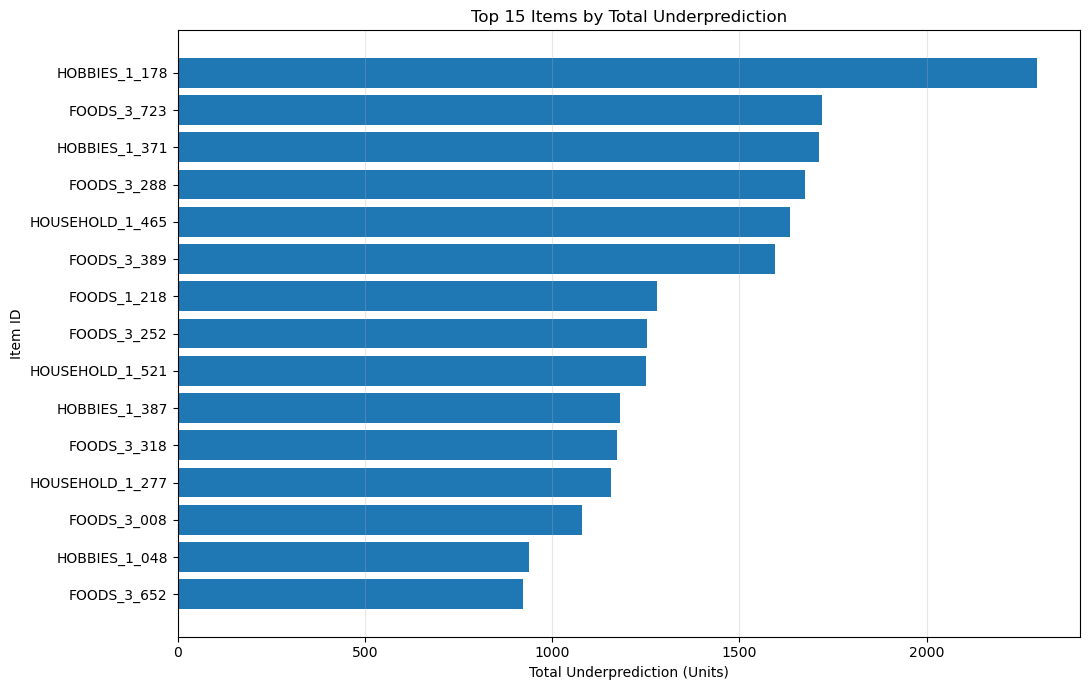

In [142]:
# Day 6: Top 15 items by total underprediction

error_feature_analysis["underprediction"] = (
    error_feature_analysis["actual_sales"]
    - error_feature_analysis["predicted_sales"]
).clip(lower=0)

top_underpredicted_items = (
    error_feature_analysis
    .groupby("item_id")
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        total_underprediction=("underprediction", "sum"),
        MAE=("absolute_error", "mean")
    )
    .sort_values("total_underprediction", ascending=False)
    .head(15)
    .reset_index()
)

print(top_underpredicted_items.to_string(index=False))

# SVG chart
fig, ax = plt.subplots(figsize=(11, 7))

plot_data = top_underpredicted_items.sort_values(
    "total_underprediction"
)

ax.barh(
    plot_data["item_id"],
    plot_data["total_underprediction"]
)

ax.set_title("Top 15 Items by Total Underprediction")
ax.set_xlabel("Total Underprediction (Units)")
ax.set_ylabel("Item ID")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "top15_items_underprediction.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

### Compare Underprediction Across Product Categories

 category  observations  total_actual_sales  total_predicted_sales  total_underprediction      MAE  underprediction_per_observation
    FOODS        181542              276852          273890.844817           96154.420268 1.042997                         0.529654
  HOBBIES         76983               57366           58661.812673           28900.295948 0.767655                         0.375411
HOUSEHOLD        124475              110408          112169.450915           44142.918167 0.723417                         0.354633


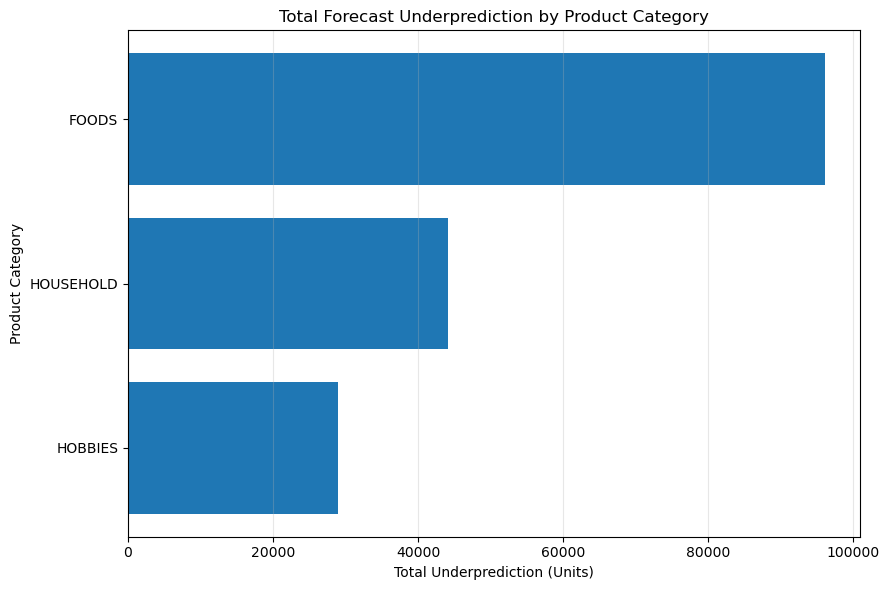

In [143]:
# Day 6: Underprediction by product category

error_feature_analysis["category"] = (
    error_feature_analysis["item_id"].str.split("_").str[0]
)

category_error_analysis = (
    error_feature_analysis
    .groupby("category")
    .agg(
        observations=("actual_sales", "size"),
        total_actual_sales=("actual_sales", "sum"),
        total_predicted_sales=("predicted_sales", "sum"),
        total_underprediction=("underprediction", "sum"),
        MAE=("absolute_error", "mean")
    )
    .reset_index()
)

category_error_analysis["underprediction_per_observation"] = (
    category_error_analysis["total_underprediction"]
    / category_error_analysis["observations"]
)

print(category_error_analysis.to_string(index=False))

# SVG chart
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = category_error_analysis.sort_values(
    "total_underprediction"
)

ax.barh(
    plot_data["category"],
    plot_data["total_underprediction"]
)

ax.set_title("Total Forecast Underprediction by Product Category")
ax.set_xlabel("Total Underprediction (Units)")
ax.set_ylabel("Product Category")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "underprediction_by_category.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

### Analyze Forecast Bias by Product Category

 category  observations  average_actual  average_predicted  mean_signed_error      MAE  total_actual  total_predicted   WAPE_pct
    FOODS        181542        1.525002           1.508691           0.016311 1.042997        276852    273890.844817  68.393107
  HOBBIES         76983        0.745178           0.762010          -0.016832 0.767655         57366     58661.812673 103.016429
HOUSEHOLD        124475        0.886989           0.901140          -0.014151 0.723417        110408    112169.450915  81.558662


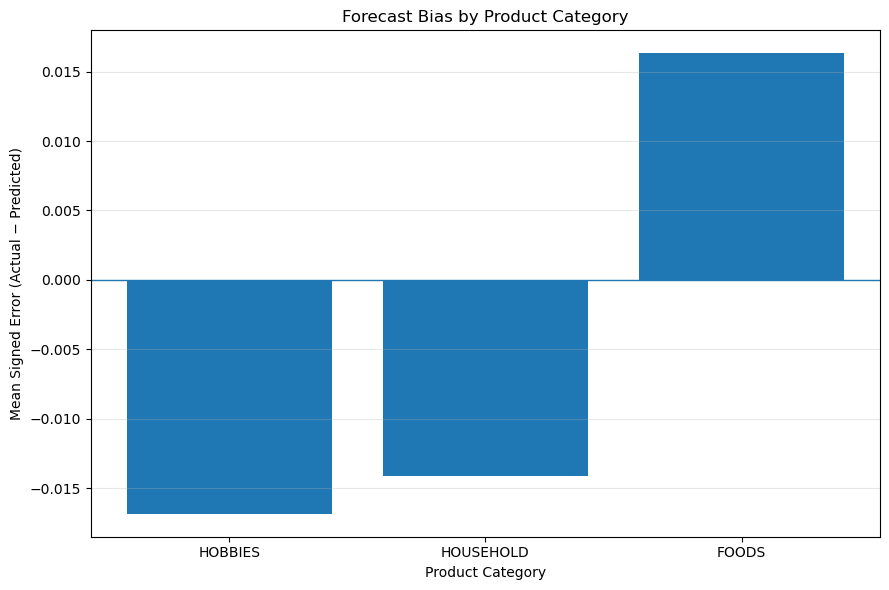

In [144]:
# Day 6: Forecast bias by product category

error_feature_analysis["category"] = (
    error_feature_analysis["item_id"].str.split("_").str[0]
)

error_feature_analysis["signed_error"] = (
    error_feature_analysis["actual_sales"]
    - error_feature_analysis["predicted_sales"]
)

category_bias = (
    error_feature_analysis
    .groupby("category")
    .agg(
        observations=("signed_error", "size"),
        average_actual=("actual_sales", "mean"),
        average_predicted=("predicted_sales", "mean"),
        mean_signed_error=("signed_error", "mean"),
        MAE=("absolute_error", "mean"),
        total_actual=("actual_sales", "sum"),
        total_predicted=("predicted_sales", "sum")
    )
    .reset_index()
)

category_bias["WAPE_pct"] = (
    error_feature_analysis.groupby("category")["absolute_error"].sum().values
    / category_bias["total_actual"].replace(0, float("nan"))
    * 100
)

print(category_bias.to_string(index=False))

# SVG chart: positive = underprediction, negative = overprediction
fig, ax = plt.subplots(figsize=(9, 6))

plot_data = category_bias.sort_values("mean_signed_error")

ax.bar(
    plot_data["category"],
    plot_data["mean_signed_error"]
)

ax.axhline(0, linewidth=1)
ax.set_title("Forecast Bias by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Mean Signed Error (Actual − Predicted)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "forecast_bias_by_category.svg",
    format="svg",
    bbox_inches="tight"
)
plt.show()

### Summarize Forecast Error Findings

In [145]:
# Day 6: Overall forecast error summary

total_actual = error_feature_analysis["actual_sales"].sum()
total_predicted = error_feature_analysis["predicted_sales"].sum()
total_absolute_error = error_feature_analysis["absolute_error"].sum()

overall_summary = pd.DataFrame({
    "Metric": [
        "Test observations",
        "Total actual sales",
        "Total predicted sales",
        "Overall MAE",
        "Overall WAPE (%)",
        "Total underprediction (units)",
        "Total overprediction (units)",
        "Overprediction observations (%)",
        "Underprediction observations (%)"
    ],
    "Value": [
        len(error_feature_analysis),
        total_actual,
        total_predicted,
        error_feature_analysis["absolute_error"].mean(),
        total_absolute_error / total_actual * 100,
        error_feature_analysis["underprediction"].sum(),
        (
            error_feature_analysis["predicted_sales"]
            - error_feature_analysis["actual_sales"]
        ).clip(lower=0).sum(),
        (
            error_feature_analysis["predicted_sales"]
            > error_feature_analysis["actual_sales"]
        ).mean() * 100,
        (
            error_feature_analysis["actual_sales"]
            > error_feature_analysis["predicted_sales"]
        ).mean() * 100
    ]
})

print(overall_summary.to_string(index=False))

# Save summary as CSV for project documentation
overall_summary.to_csv(
    "day6_overall_error_summary.csv",
    index=False
)

print("\nSaved: day6_overall_error_summary.csv")

                          Metric         Value
               Test observations 383000.000000
              Total actual sales 444626.000000
           Total predicted sales 444722.108406
                     Overall MAE      0.883789
                Overall WAPE (%)     76.129461
   Total underprediction (units) 169197.634384
    Total overprediction (units) 169293.742789
 Overprediction observations (%)     68.884073
Underprediction observations (%)     28.974935

Saved: day6_overall_error_summary.csv
